# Kenya Land Valuation: Data Preparation and Feature Engineering

This notebook is **Notebook 1 of 3** in the Kenya land price project. It takes raw **Property24 Kenya** land listings (`property24_kenya_final.csv`, 2,668 scraped rows) and runs the full data preparation and feature engineering pipeline, ending at the engineered dataset **`kenya_land_engineered_final.parquet`** (1,094 records, 40 columns). Exploratory data analysis and modelling are handled in separate notebooks (Notebook 2 — EDA, Notebook 3 — Modelling).

The pipeline runs in two parts. **Part 1** (Phases 0–4) audits and deduplicates the listings (2,668 → 1,094 records), standardises prices and sizes, geocodes every listing through a five-level waterfall, engineers proximity features, and corrects county assignments. **Part 2** (Phases 5–10) adds amenities, accessibility and infrastructure scores from OpenStreetMap and the listing descriptions, assembles the final engineered dataset, audits it, and (Phase 10) exports the backend artefacts.

**How to run** — run the cells in order on Google Colab with Google Drive mounted (Cell 0.1 installs the dependencies; Cell 0.2 mounts Drive and creates the project folders). Each phase saves a checkpoint parquet to Google Drive, so you can resume a session from the latest checkpoint without reprocessing the earlier phases (Phases 0 and 9 are audit-only and save no parquet — see the Pipeline Summary below for the exact checkpoint files).


## Contents

**Parts**

- [Part 1: Data Preparation and Feature Engineering (Phases 0–4)](#part-1)
- [Part 2: Feature Scoring and Final Assembly (Phases 5–10)](#part-2)

**Phases**

- [Phase 0 — Environment Setup & Data Audit](#phase-0)
- [Phase 1 — Price Standardisation](#phase-1)
- [Phase 2 — Size Standardisation](#phase-2)
- [Phase 3 — Geocoding](#phase-3)
- [Phase 4 — Proximity Features and County Correction](#phase-4)
- [Phase 5 — Amenities Score](#phase-5)
- [Phase 6 — Accessibility Score](#phase-6)
- [Phase 7 — Infrastructure Score](#phase-7)
- [Phase 8 — Derived Columns and Final Assembly](#phase-8)
- [Phase 9 — Quality Audit and Sign-Off](#phase-9)
- [Phase 10 — Exports for the Backend](#phase-10)


## Pipeline Summary

### 1. Phase-by-phase overview

| Phase | Purpose | Input | Output checkpoint | Key columns created |
|---|---|---|---|---|
| **0 — Environment Setup & Data Audit** | Install dependencies, mount Drive, audit the raw data, drop duplicates (2,668 → 1,094 records) | `data/raw/property24_kenya_final.csv` | — (no parquet; audit chart `outputs/phase0_audit.png`) | `desc_length` (audit helper, not kept in the final dataset) |
| **1 — Price Standardisation** | Parse mixed KSh / USD / M/B shorthand / "Price on Request" strings into numeric KSh with a quality flag; log transform | Phase 0 records (in memory) | `data/interim/phase1_price.parquet` | `price_ksh`, `price_flag`, `log_price_ksh` |
| **2 — Size Standardisation** | Convert acres / hectares / square metres / square feet / plot notation to decimal acres; NLP fallback mines the description; log transform | Phase 1 records (in memory) | `data/interim/phase2_size.parquet` | `size_acres`, `size_source`, `log_size_acres` |
| **3 — Geocoding** | Five-level waterfall: Plus Code → street address → NLP landmarks → location town → county centroid | Phase 2 records (in memory) | `data/interim/phase3_geocoded.parquet` | `latitude`, `longitude`, `geocode_source`, `geocode_confidence` |
| **4 — Proximity Features and County Correction** | Haversine distances to Nairobi CBD, the county town and the nearest water body; assign a reference city; then re-assign county via a spatial join on the GADM shapefile, a town dictionary, and Nominatim, and recalculate reference-city distances | Phase 3 records (in memory); the county correction (Cells 4.8–4.14) reloads `phase4_proximity.parquet` + `data/osm/kenya_counties.gpkg` | `data/interim/phase4_proximity.parquet` (Cells 4.1–4.7) and `data/interim/phase4b_county_fixed.parquet` (Cells 4.8–4.14) | `county` (corrected), `dist_to_nairobi_km`, `dist_to_county_town_km` (recalculated), `dist_to_water_body_km`, `reference_city`, `reference_city_dist_km` |
| **5 — Amenities Score** | Nearest-POI distance per amenity → gravity score `weight * exp(-beta * distance_km)` → 0–100 score with description-keyword floors | `phase4b_county_fixed.parquet` + `data/osm/kenya_pois.gpkg` (extracted from `kenya-latest.osm.pbf`) | `data/interim/phase5_amenities.parquet` (per-amenity caches in `data/interim/amenity_cache/`) | `amenities_score`, `amenities_score_osm` |
| **6 — Accessibility Score** | Road gravity score (50%) + reference-city decay (30%) + Nairobi decay (20%) → 0–100 score | `phase5_amenities.parquet` + `data/osm/kenya_roads.gpkg` | `data/interim/phase6_accessibility.parquet` (mid-phase: `data/interim/phase6_roads_checkpoint.parquet`) | `accessibility_score`, `accessibility_score_osm` |
| **7 — Infrastructure Score** | Regex extraction of water / electricity / fencing / structure / internal-road keywords from descriptions, with mutual-exclusivity rules and county-median imputation | `phase6_accessibility.parquet` | `data/interim/phase7_infrastructure.parquet` | `infrastructure_score`, `infra_source`, the ten `infra_<item>` 0/1 columns |
| **8 — Derived Columns and Final Assembly** | Compute the target variables and keep only the ordered `FINAL_COLUMNS` (40 columns) | `phase7_infrastructure.parquet` | `data/interim/kenya_land_engineered_final.parquet` + `data/raw/kenya_land_engineered_final.csv` | `price_per_acre`, `log_price_per_acre` |
| **9 — Quality Audit and Sign-Off** | Completeness, coordinate, score-range, outlier and correlation checks; automated sign-off checklist | `kenya_land_engineered_final.parquet` | — (no parquet; audit chart `outputs/phase9_quality_audit.png`) | — |
| **10 — Exports for the Backend** | Export the scoring parameters, Phase 4 reference lists, feature manifest, parity fixture and data-sources note for the backend, from live variables | `kenya_land_engineered_final.parquet` | `data/interim/backend_exports/` (scoring_params.json, reference_data.json, feature_manifest.json, parity_fixture.parquet, data_sources.txt) | — (exports only; no new dataframe columns) |

> **File-name note:** the county-correction checkpoint keeps its old name `phase4b_county_fixed.parquet` on purpose — Phase 5 loads it by that exact name, so renaming the file would break the pipeline.

### 2. Flow

```text
raw CSV (property24_kenya_final.csv)
      |
      v
price cleaning        Phase 1    -> phase1_price.parquet
      |
      v
size cleaning         Phase 2    -> phase2_size.parquet
      |
      v
geocoding             Phase 3    -> phase3_geocoded.parquet
      |
      v
proximity             Phase 4    -> phase4_proximity.parquet
      |
      v
county fix            Phase 4    -> phase4b_county_fixed.parquet
      |
      v
amenities             Phase 5    -> phase5_amenities.parquet
      |
      v
accessibility         Phase 6    -> phase6_accessibility.parquet
      |
      v
infrastructure        Phase 7    -> phase7_infrastructure.parquet
      |
      v
final dataset         Phase 8    -> kenya_land_engineered_final.parquet
      |
      +----> Notebook 2 (EDA)
      |
      +----> Notebook 3 (Modelling)
```

      |
      +----> backend exports    Phase 10   -> data/interim/backend_exports/


## Handoff to Downstream Notebooks

This is Notebook 1 of 3. Notebook 2 (EDA) and Notebook 3 (Modelling) should consume the
artefacts listed here instead of re-running the pipeline.

### Files a downstream notebook needs

| File | Path on Google Drive | Produced by |
|---|---|---|
| Final engineered dataset (parquet) | `data/interim/kenya_land_engineered_final.parquet` | Cell 8.3 (`CHECKPOINT_OUT`) |
| CSV copy of the final dataset | `data/raw/kenya_land_engineered_final.csv` (saved to the `data/raw` folder) | Cell 8.3 |
| Kenya county boundaries (GADM) | `data/osm/kenya_counties.gpkg` | Cell 4.9 — downloads GADM `gadm41_KEN.gpkg` from UC Davis if the file is not already on Drive |

All paths are relative to `PROJECT_ROOT = /content/drive/MyDrive/kenya_land_valuation` (Cell 0.2).
Example full path: `/content/drive/MyDrive/kenya_land_valuation/data/interim/kenya_land_engineered_final.parquet`.

Other artefacts produced by this notebook but not required downstream: the per-amenity caches in
`data/interim/amenity_cache/` (Phase 5), `data/osm/kenya_pois.gpkg` (Cell 5.2), `data/osm/kenya_roads.gpkg`
(Cell 6.0), and the audit charts `outputs/phase0_audit.png` (Cell 0.9) and `outputs/phase9_quality_audit.png` (Cell 9.7).

### Drive folder names used

`data/raw`, `data/interim`, `data/processed`, `data/osm`, `outputs` — all created by Cell 0.2.

### Final column list (`FINAL_COLUMNS`, Cell 8.2 — 40 columns, in order)

`listing_url`, `listing_no`, `title`, `location`, `prop_type`, `list_date`, `price_ksh`, `price_flag`,
`log_price_ksh`, `size_acres`, `size_source`, `log_size_acres`, `latitude`, `longitude`, `geocode_source`,
`geocode_confidence`, `county`, `dist_to_nairobi_km`, `dist_to_county_town_km`, `dist_to_water_body_km`,
`reference_city`, `reference_city_dist_km`, `amenities_score`, `accessibility_score`,
`amenities_score_osm`, `accessibility_score_osm`, `infrastructure_score`, `infra_source`,
`infra_borehole`, `infra_piped_water`, `infra_river_water`, `infra_water_tank`, `infra_grid_electric`,
`infra_solar_electric`, `infra_full_fence`, `infra_partial_fence`, `infra_structures`,
`infra_internal_road`, `price_per_acre`, `log_price_per_acre`

### Run order — once vs every session

| Cells | When to run |
|---|---|
| 0.1–0.3 (install dependencies, mount Drive, imports) | Every session |
| 0.4–4.7 (Phases 0–3 and the proximity half of Phase 4) | Every session — Phases 0–3 run in memory; Cell 4.7 saves `phase4_proximity.parquet` |
| 4.8 (load Phase 4 checkpoint) | Every session — also the resume point when restarting the county correction |
| 4.9 (download county shapefile) | Once — auto-skips when `data/osm/kenya_counties.gpkg` already exists on Drive |
| 4.10–4.14 (county correction and its checkpoint) | Every session |
| 5.1 (download `.osm.pbf`), 5.2 (extract POI GPKG) | Once per project — auto-skip if the files already exist on Drive |
| 5.0, 5.3–5.6 | Every session (5.3 copies the GPKG to local disk once per session; 5.5 skips already-cached amenities) |
| 6.0 (extract roads from PBF) | Once only — comment the cell out permanently after `data/osm/kenya_roads.gpkg` is saved |
| 6.1–6.10 | Every session — if a session crashes after Cell 6.4, use the resume block to reload `phase6_roads_checkpoint.parquet` instead of re-running Cells 6.2–6.4 |
| 7.0–9.8 | Every session — each phase's first cell loads its checkpoint |
| 10.0–10.6 (backend exports) | After 9.8 in the SAME session — Phase 10 reads live variables from Phases 4–7; Cell 10.0 fails with a clear message if one is missing |

### Backend exports (Phase 10)

`data/interim/backend_exports/` (next to the final parquet) receives `scoring_params.json`,
`reference_data.json`, `feature_manifest.json`, `parity_fixture.parquet` and
`data_sources.txt`, all exported from live variables. Cell 10.0 guards the required
Phase 4–7 variables.


<a id="part-1"></a>

# Part 1: Data Preparation and Feature Engineering (Phases 0–4)

Part 1 prepares raw Property24 Kenya listings for modelling, covering:

- **Phase 0** — Environment setup and data audit
- **Phase 1** — Price standardisation
- **Phase 2** — Size standardisation
- **Phase 3** — Geocoding
- **Phase 4** — Proximity features and county correction

Run each cell in order. Every phase from 1 onwards saves a checkpoint parquet to Google Drive so you can resume without reprocessing.


<a id="phase-0"></a>

## Phase 0 — Environment Setup & Data Audit

### Cell 0.1 — Install Dependencies

Run this every time you start a new Colab session. Packages are not persisted across sessions.


In [1]:
!pip install geopandas osmnx geopy openlocationcode spacy pyarrow fastparquet tqdm -q
!python -m spacy download en_core_web_md -q

print("All dependencies installed successfully")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
All dependencies installed successfully


### Cell 0.2 — Mount Google Drive

All checkpoints and outputs are written to Google Drive so work persists between sessions.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os

PROJECT_ROOT = "/content/drive/MyDrive/kenya_land_valuation"
RAW_DATA     = f"{PROJECT_ROOT}/data/raw"
INTERIM_DATA = f"{PROJECT_ROOT}/data/interim"
PROCESSED    = f"{PROJECT_ROOT}/data/processed"
OSM_DATA     = f"{PROJECT_ROOT}/data/osm"
OUTPUTS      = f"{PROJECT_ROOT}/outputs"

for folder in [RAW_DATA, INTERIM_DATA, PROCESSED, OSM_DATA, OUTPUTS]:
    os.makedirs(folder, exist_ok=True)

print("Google Drive mounted and project folders ready")
print(f"Project root: {PROJECT_ROOT}")

Mounted at /content/drive
Google Drive mounted and project folders ready
Project root: /content/drive/MyDrive/kenya_land_valuation


### Cell 0.3 — Imports

All libraries used across the full pipeline are imported here. Centralising imports makes it easier to
track dependencies and spot version conflicts early.


In [3]:
import pandas as pd
import numpy as np
import re
import warnings
warnings.filterwarnings("ignore")

import geopandas as gpd
from shapely.geometry import Point
import osmnx as ox
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter
from openlocationcode import openlocationcode as olc

import spacy
nlp = spacy.load("en_core_web_md")

from tqdm import tqdm
tqdm.pandas()

import matplotlib.pyplot as plt
import seaborn as sns

print("All imports successful")

All imports successful


### Cell 0.4 — Load Raw Data


In [4]:
df = pd.read_csv(f"{RAW_DATA}/property24_kenya_finals.csv")

print(f"Dataset loaded: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"\nColumns: {list(df.columns)}")

Dataset loaded: 5875 rows, 12 columns

Columns: ['listing_no', 'title', 'price', 'location', 'street_address', 'erf_size', 'property_type', 'list_date', 'description', 'listing_url', 'prop_type', 'size']


### Cell 0.5 — Data Audit

Inspect data types, null rates, and sample values for the columns most critical to this project.
This is your ground truth before any transformations are applied.


In [5]:
print("=" * 60)
print("DATA TYPES")
print("=" * 60)
print(df.dtypes)

print("\n" + "=" * 60)
print("NULL COUNTS & COMPLETENESS")
print("=" * 60)
null_summary = pd.DataFrame({
    "null_count"  : df.isnull().sum(),
    "null_pct"    : (df.isnull().sum() / len(df) * 100).round(2),
    "filled_count": df.notnull().sum(),
    "filled_pct"  : (df.notnull().sum() / len(df) * 100).round(2)
})
print(null_summary)

print("\n" + "=" * 60)
print("SAMPLE VALUES — PRICE COLUMN")
print("=" * 60)
print(df["price"].dropna().unique()[:30])

print("\n" + "=" * 60)
print("SAMPLE VALUES — SIZE COLUMN")
print("=" * 60)
print(df["size"].dropna().unique()[:30])

print("\n" + "=" * 60)
print("SAMPLE VALUES — STREET ADDRESS")
print("=" * 60)
print(df["street_address"].dropna().unique()[:20])

print("\n" + "=" * 60)
print("SAMPLE VALUES — LOCATION")
print("=" * 60)
print(df["location"].dropna().unique()[:20])

print("\n" + "=" * 60)
print("PLUS CODE DETECTION")
print("=" * 60)
plus_code_pattern = r'[A-Z0-9]{4}\+[A-Z0-9]{2,3}'
has_plus_code = df["street_address"].dropna().str.contains(plus_code_pattern, regex=True)
print(f"Records with Plus Code : {has_plus_code.sum()}")
print(f"Records without        : {(~has_plus_code).sum()}")
print(f"Street address nulls   : {df['street_address'].isnull().sum()}")

print("\n" + "=" * 60)
print("DESCRIPTION LENGTH DISTRIBUTION")
print("=" * 60)
df["desc_length"] = df["description"].fillna("").apply(len)
print(df["desc_length"].describe())
short_desc = (df["desc_length"] < 50).sum()
print(f"\nDescriptions under 50 chars (too short for NLP): {short_desc}")

DATA TYPES
listing_no         int64
title             object
price             object
location          object
street_address    object
erf_size          object
property_type     object
list_date         object
description       object
listing_url       object
prop_type         object
size              object
dtype: object

NULL COUNTS & COMPLETENESS
                null_count  null_pct  filled_count  filled_pct
listing_no               0      0.00          5875      100.00
title                  222      3.78          5653       96.22
price                  394      6.71          5481       93.29
location               462      7.86          5413       92.14
street_address        3549     60.41          2326       39.59
erf_size              3688     62.77          2187       37.23
property_type         3591     61.12          2284       38.88
list_date             3591     61.12          2284       38.88
description            462      7.86          5413       92.14
listing_url      

### Cell 0.6 — Duplicate Detection

Check for duplicates across multiple signals: exact row matches, duplicate listing IDs, duplicate URLs,
and same title+location or price+size+location combinations. Always inspect before dropping.


In [6]:
print("=" * 60)
print("DUPLICATE ANALYSIS")
print("=" * 60)

full_dupes         = df.duplicated().sum()
listing_dupes      = df.duplicated(subset=["listing_no"]).sum()
url_dupes          = df.duplicated(subset=["listing_url"]).sum()
title_loc_dupes    = df.duplicated(subset=["title", "location"]).sum()
price_size_loc_dupes = df.duplicated(subset=["price", "size", "location"]).sum()

print(f"\nFull row duplicates       : {full_dupes}")
print(f"Duplicate listing_no      : {listing_dupes}")
print(f"Duplicate listing_url     : {url_dupes}")
print(f"Duplicate title+location  : {title_loc_dupes}")
print(f"Duplicate price+size+loc  : {price_size_loc_dupes}")
print(f"\nTotal records before dedup: {len(df)}")

DUPLICATE ANALYSIS

Full row duplicates       : 0
Duplicate listing_no      : 0
Duplicate listing_url     : 0
Duplicate title+location  : 3159
Duplicate price+size+loc  : 1889

Total records before dedup: 5875


### Cell 0.7 — Inspect Duplicates

Always review what you are about to drop. Confirm that duplicates are genuine re-listings
and not separate properties that happen to share metadata.


In [7]:
dupe_mask = df.duplicated(subset=["listing_no"], keep=False)
print("Sample of duplicate listing_no records:")
print(df[dupe_mask][["listing_no", "title", "price", "location", "list_date"]]
      .sort_values("listing_no")
      .head(20)
      .to_string())

Sample of duplicate listing_no records:
Empty DataFrame
Columns: [listing_no, title, price, location, list_date]
Index: []


### Cell 0.8 — Drop Duplicates

Three-tier deduplication in order of confidence: exact row matches first (safest),
then duplicate listing IDs (keeping the most recent), then duplicate URLs.


In [8]:
print(f"Records before deduplication: {len(df)}")

df = df.drop_duplicates()
print(f"After dropping full-row dupes : {len(df)}")

df = df.sort_values("list_date", ascending=False)
df = df.drop_duplicates(subset=["listing_no"], keep="first")
print(f"After dropping dupe listing_no: {len(df)}")

df = df.drop_duplicates(subset=["listing_url"], keep="first")
print(f"After dropping dupe URLs      : {len(df)}")

df = df.reset_index(drop=True)
print(f"\nFinal record count: {len(df)}")

Records before deduplication: 5875
After dropping full-row dupes : 5875
After dropping dupe listing_no: 5875
After dropping dupe URLs      : 5875

Final record count: 5875


### Cell 0.9 — Visual Audit

Six charts covering property type distribution, description length, geocoding starting points,
null patterns, top locations, and listing date spread. Saved to the outputs folder.


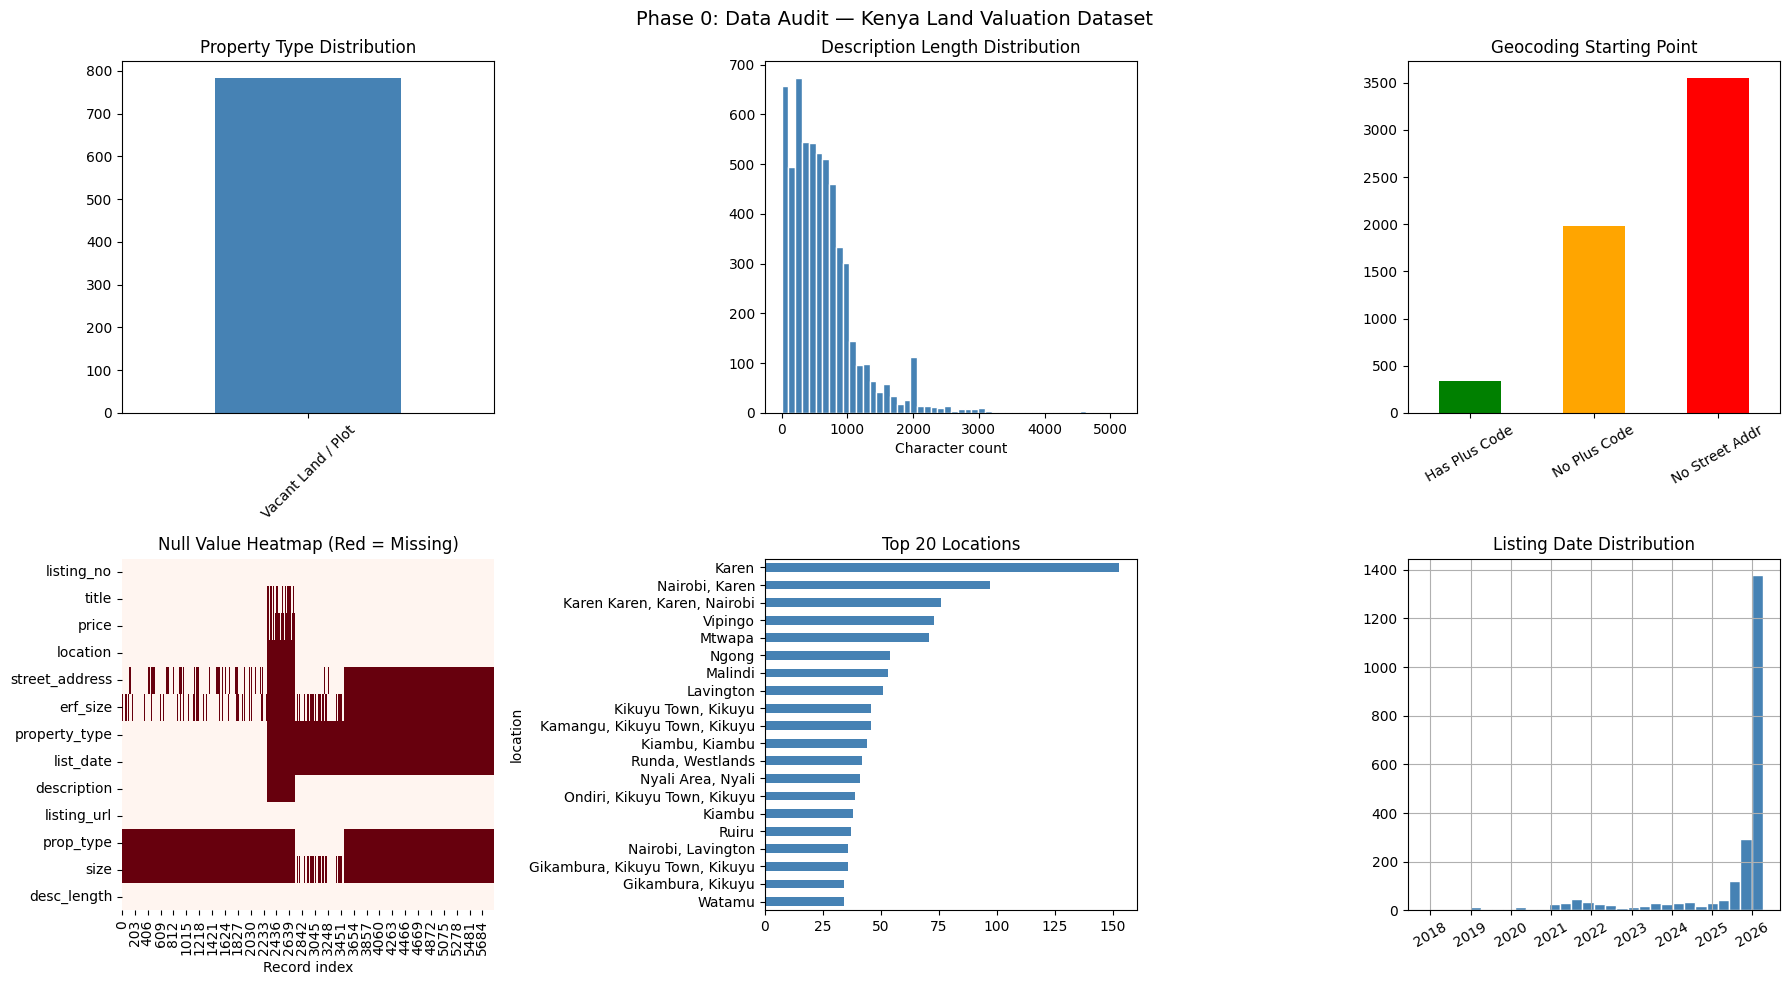

Audit chart saved to outputs folder


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Phase 0: Data Audit — Kenya Land Valuation Dataset", fontsize=14)

df["prop_type"].value_counts().plot(kind="bar", ax=axes[0, 0], color="steelblue")
axes[0, 0].set_title("Property Type Distribution")
axes[0, 0].set_xlabel("")
axes[0, 0].tick_params(axis="x", rotation=45)

axes[0, 1].hist(df["desc_length"], bins=50, color="steelblue", edgecolor="white")
axes[0, 1].set_title("Description Length Distribution")
axes[0, 1].set_xlabel("Character count")

geocode_preview = pd.Series({
    "Has Plus Code" : has_plus_code.sum(),
    "No Plus Code"  : (~has_plus_code).sum(),
    "No Street Addr": df["street_address"].isnull().sum()
})
geocode_preview.plot(kind="bar", ax=axes[0, 2], color=["green", "orange", "red"])
axes[0, 2].set_title("Geocoding Starting Point")
axes[0, 2].tick_params(axis="x", rotation=30)

sns.heatmap(df.isnull().astype(int).T, ax=axes[1, 0], cbar=False, cmap="Reds", yticklabels=True)
axes[1, 0].set_title("Null Value Heatmap (Red = Missing)")
axes[1, 0].set_xlabel("Record index")

df["location"].value_counts().head(20).plot(kind="barh", ax=axes[1, 1], color="steelblue")
axes[1, 1].set_title("Top 20 Locations")
axes[1, 1].invert_yaxis()

if df["list_date"].notnull().sum() > 0:
    # Convert list_date to datetime to allow plotting a temporal histogram
    dates = pd.to_datetime(df["list_date"], errors="coerce").dropna()
    if len(dates) > 0:
        dates.hist(ax=axes[1, 2], bins=30, color="steelblue", edgecolor="white")
        axes[1, 2].set_title("Listing Date Distribution")
        axes[1, 2].tick_params(axis="x", rotation=30)
    else:
        axes[1, 2].set_title("List Date — Unparseable Dates")
else:
    axes[1, 2].set_title("List Date — No Data")

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/phase0_audit.png", dpi=150, bbox_inches="tight")
plt.show()
print("Audit chart saved to outputs folder")

<a id="phase-1"></a>

---
## Phase 1 — Price Standardisation

The raw `price` column contains mixed currencies (KSh and USD), shorthand notation (20M, 1.5B),
comma and space separators, and non-price strings (POA, negotiable). This phase parses every
value into a consistent float in KSh, assigns a quality flag per record, and produces a
log-transformed column ready for modelling.


### Cell 1.1 — Price Pattern Audit

Count how many records match each format before writing any parsing logic.
This drives the priority ordering of the cleaning function.


In [10]:
print("=" * 65)
print("PRICE PATTERN AUDIT")
print("=" * 65)

print(f"\nNull prices     : {df['price'].isnull().sum()}")
print(f"Non-null prices : {df['price'].notnull().sum()}")

price_str = df["price"].dropna().astype(str).str.strip()

patterns = {
    "Contains 'KSh' or 'Ksh'" : price_str.str.contains(r'[Kk][Ss][Hh]', regex=True).sum(),
    "Contains 'USD' or '$'"   : price_str.str.contains(r'USD|\$', regex=True).sum(),
    "Contains 'M' shorthand"  : price_str.str.contains(r'\d+(\.\d+)?M', regex=True).sum(),
    "Contains 'B' shorthand"  : price_str.str.contains(r'\d+(\.\d+)?B', regex=True).sum(),
    "Price on Request / POA"  : price_str.str.contains(r'request|POA|negotiable', case=False, regex=True).sum(),
    "Contains comma separator": price_str.str.contains(r'\d,\d', regex=True).sum(),
    "Contains space separator": price_str.str.contains(r'\d \d', regex=True).sum(),
    "Numeric only (no symbol)": price_str.str.match(r'^\d[\d\s,\.]+$').sum(),
}

for label, count in patterns.items():
    print(f"  {label:<35}: {count:>6,}")

PRICE PATTERN AUDIT

Null prices     : 394
Non-null prices : 5481
  Contains 'KSh' or 'Ksh'            :  5,372
  Contains 'USD' or '$'              :      0
  Contains 'M' shorthand             :      0
  Contains 'B' shorthand             :      0
  Price on Request / POA             :     81
  Contains comma separator           :  2,309
  Contains space separator           :  3,053
  Numeric only (no symbol)           :      0


### Cell 1.2 — Price Cleaning Function

Handles every detected pattern in priority order. Returns both a numeric value and a quality flag
so you can filter or weight records downstream.

**USD exchange rate:** Update `USD_TO_KSH_RATE` if the rate has drifted significantly since the
date recorded in `USD_RATE_DATE`.


In [11]:
USD_TO_KSH_RATE = 129.50   # Rate as of early 2025 — update if needed
USD_RATE_DATE   = "2025-01"

def clean_price(raw_value):
    """
    Parse a raw price string into a float in KSh.

    Returns
    -------
    (price_ksh : float | NaN, flag : str)

    Flags
    -----
    clean         : standard KSh value
    converted_usd : was USD, converted to KSh
    missing       : null, empty, or unparseable
    negotiable    : price on request / POA / negotiable
    ambiguous     : has digits but currency is unclear
    """
    if pd.isnull(raw_value):
        return np.nan, "missing"

    text = str(raw_value).strip()

    if text == "" or text.lower() in ["nan", "none", "-", "n/a"]:
        return np.nan, "missing"

    if re.search(r'request|poa|negotiable|contact|call', text, re.IGNORECASE):
        return np.nan, "negotiable"

    is_usd = bool(re.search(r'USD|\$|usd', text))
    is_ksh = bool(re.search(r'[Kk][Ss][Hh]|KES', text))

    # Handle M / B shorthand before stripping letters
    shorthand_match = re.search(r'([\d]+(?:\.[\d]+)?)\s*([MB])', text, re.IGNORECASE)
    if shorthand_match:
        number    = float(shorthand_match.group(1))
        suffix    = shorthand_match.group(2).upper()
        price_val = number * (1_000_000 if suffix == "M" else 1_000_000_000)
        flag      = "converted_usd" if is_usd else "clean"
        if is_usd:
            price_val *= USD_TO_KSH_RATE
        return price_val, flag

    numeric_str = re.sub(r'[^\d\.]', '', text)

    if numeric_str == "" or numeric_str == ".":
        return np.nan, "missing"

    # European-style thousand separators: "20.000.000" → "20000000"
    if numeric_str.count(".") > 1:
        parts = numeric_str.split(".")
        numeric_str = "".join(parts[:-1]) + "." + parts[-1]

    try:
        price_val = float(numeric_str)
    except ValueError:
        return np.nan, "ambiguous"

    # Values below 1,000 are almost certainly parsing errors for Kenyan land prices
    if price_val < 1_000:
        return np.nan, "ambiguous"

    if is_usd:
        return price_val * USD_TO_KSH_RATE, "converted_usd"

    if not is_ksh and not is_usd:
        return price_val, "ambiguous"

    return price_val, "clean"


### Cell 1.3 — Apply Price Cleaning


In [12]:
print("Cleaning price column...")

results = df["price"].progress_apply(clean_price)
df["price_ksh"]  = results.apply(lambda x: x[0])
df["price_flag"] = results.apply(lambda x: x[1])

print("\nPrice flag distribution:")
print(df["price_flag"].value_counts())
print(f"\nSuccessfully parsed  : {df['price_ksh'].notnull().sum():,} records")
print(f"Unparseable / missing: {df['price_ksh'].isnull().sum():,} records")

Cleaning price column...


100%|██████████| 5875/5875 [00:00<00:00, 53978.56it/s]


Price flag distribution:
price_flag
clean         5362
missing        430
negotiable      81
ambiguous        2
Name: count, dtype: int64

Successfully parsed  : 5,362 records
Unparseable / missing: 513 records


### Cell 1.4 — Log Transform

Land prices in Kenya span several orders of magnitude. The log transform compresses this range,
making the distribution closer to normal and improving model training stability.
Only applied where `price_ksh` is valid and positive.


In [13]:
df["log_price_ksh"] = np.where(
    df["price_ksh"].notnull() & (df["price_ksh"] > 0),
    np.log(df["price_ksh"]),
    np.nan
)

print(f"Valid log_price_ksh values: {df['log_price_ksh'].notnull().sum():,}")

Valid log_price_ksh values: 5,362


### Cell 1.5 — Sanity Checks

Verify that the cleaned price range is plausible for Kenyan land. Flag anything below KSh 100,000
or above KSh 5 billion for manual review.


In [14]:
print("=" * 65)
print("PRICE VALIDATION — SANITY CHECKS")
print("=" * 65)

clean_prices = df[df["price_flag"] == "clean"]["price_ksh"]

print(f"\nClean prices summary (KSh):")
print(f"  Count  : {clean_prices.count():,}")
print(f"  Min    : KSh {clean_prices.min():>20,.0f}")
print(f"  Max    : KSh {clean_prices.max():>20,.0f}")
print(f"  Median : KSh {clean_prices.median():>20,.0f}")
print(f"  Mean   : KSh {clean_prices.mean():>20,.0f}")
print(f"  Std    : KSh {clean_prices.std():>20,.0f}")

LOWER_BOUND = 100_000
UPPER_BOUND = 5_000_000_000

low_outliers  = df[(df["price_ksh"] < LOWER_BOUND) & df["price_ksh"].notnull()]
high_outliers = df[(df["price_ksh"] > UPPER_BOUND) & df["price_ksh"].notnull()]

print(f"\nSuspicious low prices  (< KSh 100K) : {len(low_outliers)}")
print(f"Suspicious high prices (> KSh 5B)   : {len(high_outliers)}")

if len(low_outliers) > 0:
    print("\nLow outlier samples:")
    print(low_outliers[["price", "price_ksh", "price_flag", "location"]].head(10).to_string())

if len(high_outliers) > 0:
    print("\nHigh outlier samples:")
    print(high_outliers[["price", "price_ksh", "price_flag", "location"]].head(10).to_string())

PRICE VALIDATION — SANITY CHECKS

Clean prices summary (KSh):
  Count  : 5,362
  Min    : KSh                1,200
  Max    : KSh 8,000,000,116,984,268,706,246,418,059,231,232
  Median : KSh           25,000,000
  Mean   : KSh 1,963,298,943,318,689,351,264,540,557,312
  Std    : KSh 114,255,652,210,983,323,779,399,482,867,712

Suspicious low prices  (< KSh 100K) : 8
Suspicious high prices (> KSh 5B)   : 13

Low outlier samples:
           price  price_ksh price_flag                                   location
494    KSh 9 000     9000.0      clean                         Nairobi, Kerarapon
1038   KSh 3 000     3000.0      clean        Suna Central Migori, Migori, Migori
1219  KSh 60 000    60000.0      clean         5636+pm Mutomo, Machakos, Machakos
1754   KSh 1 200     1200.0      clean  Kimuka Trading Center Karen, Ngong, Ngong
2810  KSh 50 000    50000.0      clean                                    Malindi
2820   KSh 6 650     6650.0      clean                                    Ka

### Cell 1.6 — Visual Audit


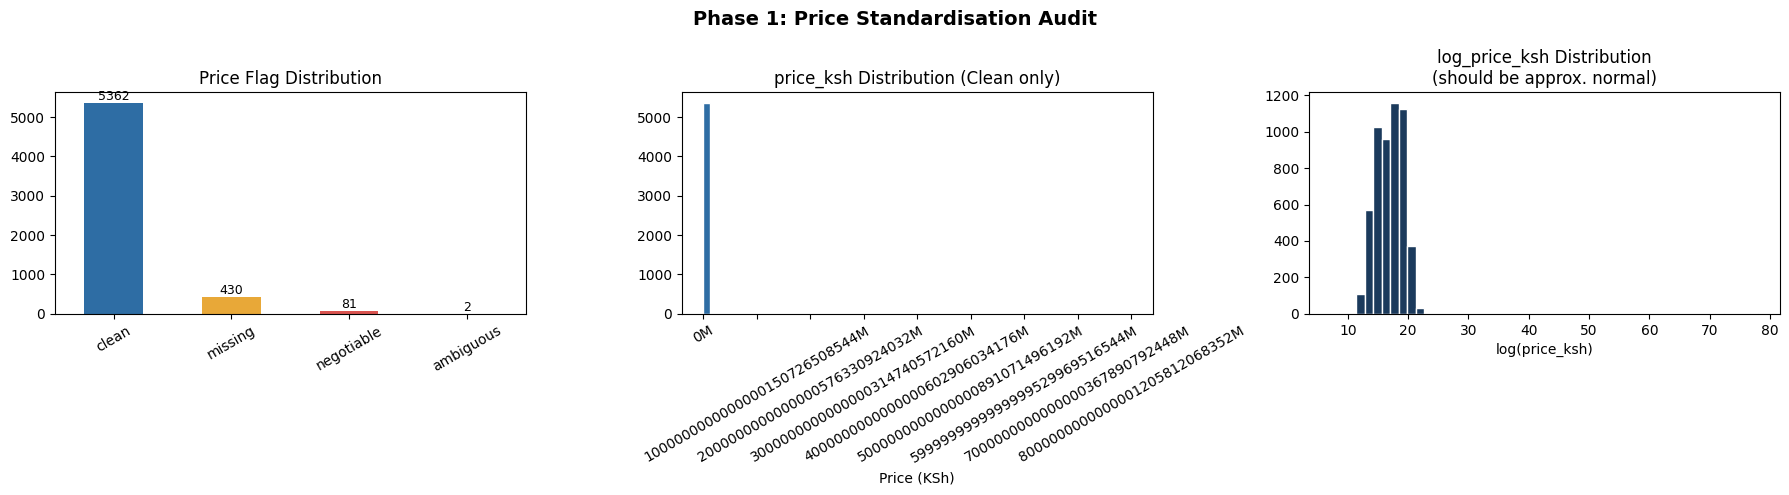

Chart saved to outputs folder.


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Phase 1: Price Standardisation Audit", fontsize=14, fontweight="bold")

df["price_flag"].value_counts().plot(
    kind="bar", ax=axes[0],
    color=["#2E6DA4", "#E8A838", "#D9534F", "#5CB85C", "#9B59B6"]
)
axes[0].set_title("Price Flag Distribution")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
for bar in axes[0].patches:
    axes[0].annotate(f'{int(bar.get_height())}',
                     (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                     ha="center", va="bottom", fontsize=9)

clean_mask = df["price_flag"] == "clean"
axes[1].hist(df.loc[clean_mask, "price_ksh"].dropna(), bins=60,
             color="#2E6DA4", edgecolor="white")
axes[1].set_title("price_ksh Distribution (Clean only)")
axes[1].set_xlabel("Price (KSh)")
axes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.0f}M'))
axes[1].tick_params(axis="x", rotation=30)

axes[2].hist(df["log_price_ksh"].dropna(), bins=50,
             color="#1B3A5C", edgecolor="white")
axes[2].set_title("log_price_ksh Distribution\n(should be approx. normal)")
axes[2].set_xlabel("log(price_ksh)")

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/phase1_price_audit.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved to outputs folder.")

### Cell 1.7 — Review Ambiguous and Converted Records

Manually inspect records that were flagged as ambiguous (currency unclear) or converted from USD.
Ambiguous records may need a pricing source fix; USD conversions depend on the exchange rate used.


In [16]:
print("=" * 65)
print("AMBIGUOUS PRICES — REVIEW THESE MANUALLY")
print("=" * 65)
ambiguous = df[df["price_flag"] == "ambiguous"][["price", "price_ksh", "location"]].head(20)
if len(ambiguous) > 0:
    print(ambiguous.to_string())
else:
    print("No ambiguous prices found.")

print("\n" + "=" * 65)
print("USD CONVERSIONS — VERIFY THESE")
print("=" * 65)
usd_records = df[df["price_flag"] == "converted_usd"][["price", "price_ksh", "location"]].head(20)
if len(usd_records) > 0:
    print(f"Exchange rate used: 1 USD = {USD_TO_KSH_RATE} KSh (as of {USD_RATE_DATE})")
    print(usd_records.to_string())
else:
    print("No USD prices found.")

AMBIGUOUS PRICES — REVIEW THESE MANUALLY
      price  price_ksh                                 location
3439  KSh 1        NaN                             Shimba Hills
5649  KSh 1        NaN  City park cresent, Parklands, Westlands

USD CONVERSIONS — VERIFY THESE
No USD prices found.


### Cell 1.8 — Phase 1 Column Summary & Save Checkpoint


In [17]:
print("=" * 65)
print("PHASE 1 OUTPUT — COLUMN SUMMARY")
print("=" * 65)

cols = ["price_ksh", "price_flag", "log_price_ksh"]
summary = pd.DataFrame({
    "dtype"   : [str(df[c].dtype) for c in cols],
    "non_null": [df[c].notnull().sum() for c in cols],
    "null"    : [df[c].isnull().sum() for c in cols],
}, index=cols)
print(summary.to_string())

print(f"\nRecords retained : {len(df):,}")
print(f"Prices parseable : {df['price_ksh'].notnull().sum():,} ({df['price_ksh'].notnull().sum()/len(df)*100:.1f}%)")

df.to_parquet(f"{INTERIM_DATA}/phase1_price.parquet", index=False)
print(f"\nCheckpoint saved: phase1_price.parquet")

PHASE 1 OUTPUT — COLUMN SUMMARY
                 dtype  non_null  null
price_ksh      float64      5362   513
price_flag      object      5875     0
log_price_ksh  float64      5362   513

Records retained : 5,875
Prices parseable : 5,362 (91.3%)

Checkpoint saved: phase1_price.parquet


<a id="phase-2"></a>

---
## Phase 2 — Size Standardisation

The raw `size` column contains values in acres, hectares, square metres, square feet, and
Kenyan plot notation (e.g. 50x100). Text fractions such as "half acre" also appear.
This phase converts everything to decimal acres, with an NLP fallback that mines the
description text when the size column is missing.


### Cell 2.1 — Size Pattern Audit


In [18]:
size_str = df["size"].dropna().astype(str).str.strip()

patterns = {
    "Acres"          : size_str.str.contains(r'acres?', case=False, regex=True).sum(),
    "Hectares"       : size_str.str.contains(r'ha|hectares?', case=False, regex=True).sum(),
    "Sq meters"      : size_str.str.contains(r'sq\.?\s*m|square\s*met', case=False, regex=True).sum(),
    "Sq feet"        : size_str.str.contains(r'sq\.?\s*ft|square\s*f', case=False, regex=True).sum(),
    "50x100 notation": size_str.str.contains(r'\d+\s*(by|x)\s*\d+', case=False, regex=True).sum(),
    "Text fractions" : size_str.str.contains(r'half|quarter|one\s*and', case=False, regex=True).sum(),
    "Nulls"          : df["size"].isnull().sum(),
}

for label, count in patterns.items():
    print(f"  {label:<25}: {count:>5,}")

  Acres                    :   473
  Hectares                 :    13
  Sq meters                :     0
  Sq feet                  :     0
  50x100 notation          :     0
  Text fractions           :     0
  Nulls                    : 5,389


### Cell 2.2 — Size Cleaning Function

Unit conversion constants are defined at the top. The function normalises text fractions,
handles Kenyan 50x100 plot notation, extracts the leading number, then converts to acres
based on the detected unit. Records with no unit default to acres, which is the conventional
unit for Kenyan land listings.


In [19]:
HA_TO_ACRES      = 2.4711
SQM_TO_ACRES     = 0.000247105
SQFT_TO_ACRES    = 0.0000229568
PLOT_50x100_ACRES = 0.1148   # 50x100 ft = 5,000 sqft

def clean_size(raw):
    """
    Parse a raw size string into decimal acres.

    Returns
    -------
    (size_acres : float | NaN, source : str)

    Source values: 'column' | 'missing'
    """
    if pd.isnull(raw):
        return np.nan, "missing"

    text = str(raw).strip().lower()

    if text in ["", "nan", "none", "-"]:
        return np.nan, "missing"

    text = re.sub(r'one\s*and\s*a?\s*half', '1.5', text)
    text = re.sub(r'\bhalf\b',               '0.5', text)
    text = re.sub(r'\bquarter\b',            '0.25', text)
    text = re.sub(r'\bthree\s*quarter',      '0.75', text)

    plot_match = re.search(r'(\d+)\s*(?:by|x)\s*(\d+)', text)
    if plot_match:
        sqft = float(plot_match.group(1)) * float(plot_match.group(2))
        return round(sqft * SQFT_TO_ACRES, 6), "column"

    num_match = re.search(r'([\d]+(?:\.[\d]+)?)', text)
    if not num_match:
        return np.nan, "missing"

    val = float(num_match.group(1))

    if re.search(r'ha\b|hectare', text):
        return round(val * HA_TO_ACRES, 4), "column"
    if re.search(r'sq\.?\s*m|square\s*met|sqm', text):
        return round(val * SQM_TO_ACRES, 6), "column"
    if re.search(r'sq\.?\s*ft|square\s*f|sqft', text):
        return round(val * SQFT_TO_ACRES, 6), "column"
    if re.search(r'acres?', text):
        return round(val, 4), "column"

    return round(val, 4), "column"  # default: assume acres

### Cell 2.3 — Apply to Size Column


In [20]:
results           = df["size"].apply(clean_size)
df["size_acres"]  = results.apply(lambda x: x[0])
df["size_source"] = results.apply(lambda x: x[1])

print("Size source breakdown after column cleaning:")
print(df["size_source"].value_counts())
print(f"\nMissing after column pass: {df['size_acres'].isnull().sum()}")

Size source breakdown after column cleaning:
size_source
missing    5389
column      486
Name: count, dtype: int64

Missing after column pass: 5389


### Cell 2.4 — NLP Fallback from Description

For records where the size column could not be parsed, attempt to extract a size value
from the free-text description. The same unit conversion logic is applied.
This fallback is only triggered for the records that remain null after Cell 2.3.


In [21]:
def extract_size_from_description(text):
    """
    Mine the description for size mentions as a fallback.
    Returns (size_acres : float | NaN, source : str).
    """
    if pd.isnull(text) or len(str(text)) < 20:
        return np.nan, "missing"

    text = str(text).lower()
    text = re.sub(r'one\s*and\s*a?\s*half', '1.5', text)
    text = re.sub(r'\bhalf\b',               '0.5', text)
    text = re.sub(r'\bquarter\b',            '0.25', text)

    plot_match = re.search(r'(\d+)\s*(?:by|x)\s*(\d+)', text)
    if plot_match:
        sqft = float(plot_match.group(1)) * float(plot_match.group(2))
        return round(sqft * SQFT_TO_ACRES, 6), "nlp_description"

    m = re.search(r'([\d]+(?:\.[\d]+)?)\s*[-]?\s*acres?', text)
    if m:
        return round(float(m.group(1)), 4), "nlp_description"

    m = re.search(r'([\d]+(?:\.[\d]+)?)\s*(?:ha|hectares?)', text)
    if m:
        return round(float(m.group(1)) * HA_TO_ACRES, 4), "nlp_description"

    m = re.search(r'([\d]+(?:\.[\d]+)?)\s*(?:sq\.?\s*m|sqm|square\s*met)', text)
    if m:
        return round(float(m.group(1)) * SQM_TO_ACRES, 6), "nlp_description"

    return np.nan, "missing"


missing_mask = df["size_acres"].isnull()
print(f"Records needing NLP fallback: {missing_mask.sum()}")

if missing_mask.sum() > 0:
    fallback = df.loc[missing_mask, "description"].apply(extract_size_from_description)
    df.loc[missing_mask, "size_acres"]  = fallback.apply(lambda x: x[0])
    df.loc[missing_mask, "size_source"] = fallback.apply(lambda x: x[1])

print("\nSize source breakdown after NLP fallback:")
print(df["size_source"].value_counts())

Records needing NLP fallback: 5389

Size source breakdown after NLP fallback:
size_source
nlp_description    3506
missing            1883
column              486
Name: count, dtype: int64


### Cell 2.5 — Log Transform


In [22]:
df["log_size_acres"] = np.where(
    df["size_acres"].notnull() & (df["size_acres"] > 0),
    np.log(df["size_acres"]),
    np.nan
)

print(f"Valid log_size_acres values: {df['log_size_acres'].notnull().sum():,}")

Valid log_size_acres values: 3,973


### Cell 2.6 — Sanity Checks

Flag sizes below 0.05 acres (roughly 2,178 sqft — smaller than the smallest practical Kenyan plot)
and above 50,000 acres (a generous upper bound for large ranches).


In [23]:
low_flag  = df[(df["size_acres"] < 0.05)   & df["size_acres"].notnull()]
high_flag = df[(df["size_acres"] > 50_000) & df["size_acres"].notnull()]

print(f"Suspiciously small (< 0.05 acres) : {len(low_flag)}")
print(f"Suspiciously large (> 50,000 acres): {len(high_flag)}")

if len(low_flag)  > 0:
    print(low_flag[["size", "size_acres", "location"]].to_string())
if len(high_flag) > 0:
    print(high_flag[["size", "size_acres", "location"]].to_string())

Suspiciously small (< 0.05 acres) : 34
Suspiciously large (> 50,000 acres): 0
           size  size_acres                                   location
82          NaN    0.037560       Watamu Kilifi County, Watamu, Watamu
142         NaN    0.000000           Rvxr+4ch Tatu City, Ruiru, Ruiru
549         NaN    0.000000  Nanyuki Laikipia County, Nanyuki, Nanyuki
836         NaN    0.000000            V42f+gr Malindi, Watamu, Watamu
1135        NaN    0.025946              Westlands, Westlands, Nairobi
1427        NaN    0.037560       Watamu Kilifi County, Watamu, Watamu
1792        NaN    0.000000      Tatu City Kiambu County, Ruiru, Ruiru
1793        NaN    0.000000      Tatu City Kiambu County, Ruiru, Ruiru
2750        NaN    0.000000                                   Naivasha
2957  000 Acres    0.000000                                      Ruiru
2979  000 acres    0.000000                                        Voi
2996  0.0197 Ha    0.048700                                    Malindi

### Cell 2.7 — Visual Audit


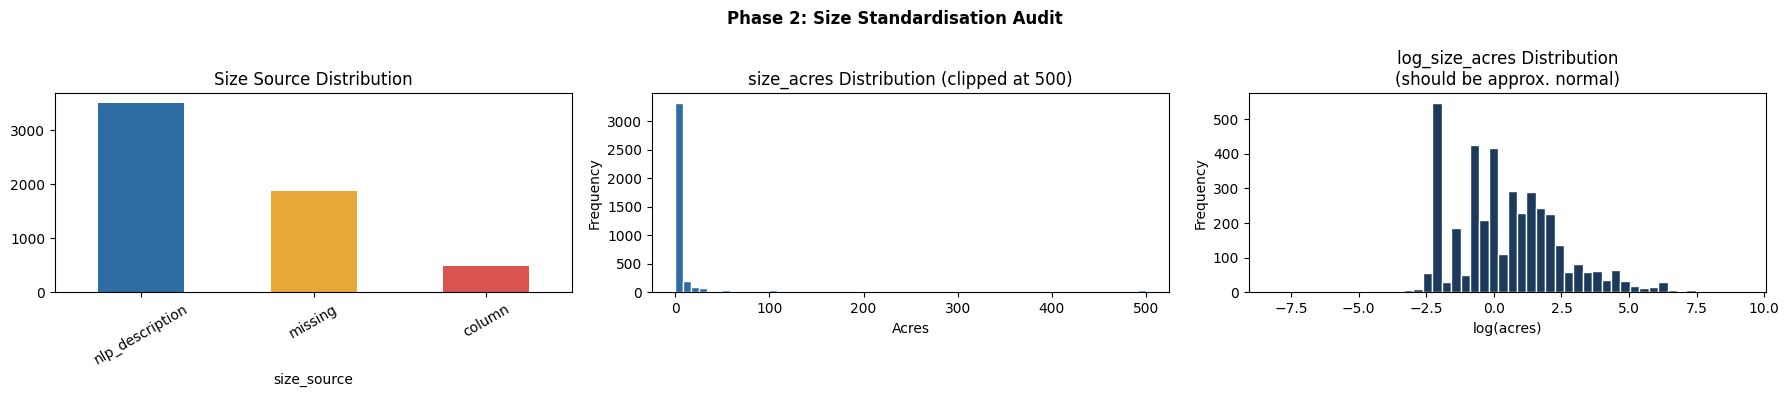

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle("Phase 2: Size Standardisation Audit", fontweight="bold")

df["size_source"].value_counts().plot(
    kind="bar", ax=axes[0], color=["#2E6DA4", "#E8A838", "#D9534F"]
)
axes[0].set_title("Size Source Distribution")
axes[0].tick_params(axis="x", rotation=30)

df["size_acres"].dropna().clip(upper=500).plot(
    kind="hist", bins=60, ax=axes[1], color="#2E6DA4", edgecolor="white"
)
axes[1].set_title("size_acres Distribution (clipped at 500)")
axes[1].set_xlabel("Acres")

df["log_size_acres"].dropna().plot(
    kind="hist", bins=50, ax=axes[2], color="#1B3A5C", edgecolor="white"
)
axes[2].set_title("log_size_acres Distribution\n(should be approx. normal)")
axes[2].set_xlabel("log(acres)")

plt.tight_layout()
plt.show()

### Cell 2.8 — Phase 2 Summary & Save Checkpoint


In [25]:
print("=" * 55)
print("PHASE 1 + 2 COMBINED COLUMN SUMMARY")
print("=" * 55)

cols = ["price_ksh", "price_flag", "log_price_ksh",
        "size_acres", "size_source", "log_size_acres"]

summary = pd.DataFrame({
    "dtype"   : [str(df[c].dtype) for c in cols],
    "non_null": [df[c].notnull().sum() for c in cols],
    "null"    : [df[c].isnull().sum() for c in cols],
    "null_pct": [(df[c].isnull().sum() / len(df) * 100).round(1) for c in cols],
}, index=cols)
print(summary.to_string())

df.to_parquet(f"{INTERIM_DATA}/phase2_size.parquet", index=False)
print("\nCheckpoint saved: phase2_size.parquet")

PHASE 1 + 2 COMBINED COLUMN SUMMARY
                  dtype  non_null  null  null_pct
price_ksh       float64      5362   513       8.7
price_flag       object      5875     0       0.0
log_price_ksh   float64      5362   513       8.7
size_acres      float64      3992  1883      32.1
size_source      object      5875     0       0.0
log_size_acres  float64      3973  1902      32.4

Checkpoint saved: phase2_size.parquet


<a id="phase-3"></a>

---
## Phase 3 — Geocoding

Assigns latitude and longitude to each listing using a five-level waterfall:

1. **Plus Code** — exact coordinates from an Open Location Code in the street address (confidence 1.0)
2. **Street address** — Nominatim geocoding of the full street address (confidence 0.8)
3. **NLP landmarks** — place names and proximity hints extracted from the description (confidence 0.5)
4. **Location town** — Nominatim geocoding of the `location` column value (confidence 0.3)
5. **County centroid** — fallback to the county's geographic centre (confidence 0.2)

Each record is tagged with a `geocode_source` and `geocode_confidence` for downstream filtering.


### Cell 3.1 — Fix Encoding Artifacts

Correct common UTF-8 mojibake characters that appear in scraped text before any string matching.


In [26]:
def fix_encoding(text):
    if pd.isnull(text):
        return text
    text = str(text)
    replacements = {
        "â€™": "'", "â€œ": '"', "â€": '"',
        "â€˜": "'", "â€": "-", "â€¢": "•",
        "Â": "", "â€": ""
    }
    for bad, good in replacements.items():
        text = text.replace(bad, good)
    return text.strip()

df["street_address"] = df["street_address"].apply(fix_encoding)
df["location"]       = df["location"].apply(fix_encoding)
df["description"]    = df["description"].apply(fix_encoding)

print("Encoding artifacts cleaned.")

Encoding artifacts cleaned.


### Cell 3.2 — County Centroids

Reference coordinates for the 47 Kenyan counties used as the Level 5 fallback when all
higher-confidence geocoding methods fail.


In [27]:
COUNTY_CENTROIDS = {
    "Nairobi"        : (-1.2921, 36.8219), "Mombasa"        : (-4.0435, 39.6682),
    "Kwale"          : (-4.1816, 39.4600), "Kilifi"         : (-3.5107, 39.9093),
    "Tana River"     : (-1.4000, 40.0000), "Lamu"           : (-2.2686, 40.9020),
    "Taita Taveta"   : (-3.4000, 38.5000), "Garissa"        : (-0.4532, 39.6461),
    "Wajir"          : ( 1.7471, 40.0573), "Mandera"        : ( 3.9366, 41.8670),
    "Marsabit"       : ( 2.3284, 37.9899), "Isiolo"         : ( 0.3540, 37.5820),
    "Meru"           : ( 0.0470, 37.6490), "Tharaka Nithi"  : (-0.3000, 37.8800),
    "Embu"           : (-0.5300, 37.4500), "Kitui"          : (-1.3671, 38.0106),
    "Machakos"       : (-1.5177, 37.2634), "Makueni"        : (-1.8036, 37.6200),
    "Nyandarua"      : (-0.1800, 36.5200), "Nyeri"          : (-0.4167, 36.9500),
    "Kirinyaga"      : (-0.5600, 37.2800), "Murang'a"       : (-0.7833, 37.0333),
    "Kiambu"         : (-1.0300, 36.8300), "Turkana"        : ( 3.1000, 35.6000),
    "West Pokot"     : ( 1.6200, 35.1200), "Samburu"        : ( 1.2000, 36.9900),
    "Trans Nzoia"    : ( 1.0566, 35.0010), "Uasin Gishu"    : ( 0.5200, 35.2699),
    "Elgeyo Marakwet": ( 0.7000, 35.5000), "Nandi"          : ( 0.1800, 35.1700),
    "Baringo"        : ( 0.8500, 35.9700), "Laikipia"       : ( 0.2000, 36.8000),
    "Nakuru"         : (-0.3031, 36.0800), "Narok"          : (-1.0800, 35.8700),
    "Kajiado"        : (-1.8500, 36.7800), "Kericho"        : (-0.3670, 35.2860),
    "Bomet"          : (-0.7800, 35.3400), "Kakamega"       : ( 0.2827, 34.7519),
    "Vihiga"         : ( 0.0800, 34.7200), "Bungoma"        : ( 0.5600, 34.5600),
    "Busia"          : ( 0.4600, 34.1100), "Siaya"          : (-0.0617, 34.2900),
    "Kisumu"         : (-0.1022, 34.7617), "Homa Bay"       : (-0.5200, 34.4600),
    "Migori"         : (-1.0634, 34.4731), "Kisii"          : (-0.6817, 34.7667),
    "Nyamira"        : (-0.5700, 34.9300),
}

print(f"County centroids loaded: {len(COUNTY_CENTROIDS)}")

County centroids loaded: 47


### Cell 3.3 — Geocoding Waterfall Functions

Three helper functions:
- `decode_plus_code` — decodes an Open Location Code to coordinates
- `extract_nlp_locations` — extracts place names and proximity hints from description text
- `geocode_row` — runs the full five-level waterfall for a single row


In [30]:
import json as _json
import time as _time
from openlocationcode import openlocationcode as olc
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

PLUS_CODE_PATTERN = r'[A-Z0-9]{4}\+[A-Z0-9]{2,3}'
KE_BOUNDS         = {"lat": (-4.72, 4.62), "lon": (33.91, 41.91)}

geolocator = Nominatim(user_agent="kenya_land_valuation_v1", timeout=10)
geocode    = RateLimiter(geolocator.geocode, min_delay_seconds=1.1)

# ---- Instrumentation: counters for HTTP calls, cache hits, exceptions, ----
# ---- and which waterfall level each row resolved at.                   ----
GEOCODE_STATS = {
    "http_calls": 0,
    "cache_hits": 0,
    "exceptions": {},  # {exception_type_name: count}
    "rows_resolved_by_level": {
        "plus_code": 0, "street_address": 0, "nlp_landmark": 0,
        "location_town": 0, "county_centroid": 0, "failed": 0,
    },
}

# ---- Disk-backed cache keyed on the normalized query string. Survives ----
# ---- runtime restarts so repeated identical queries (e.g. the same    ----
# ---- town name appearing across many listings) are geocoded once.     ----
CACHE_PATH       = f"{INTERIM_DATA}/geocode_cache.json"
CHECKPOINT_PATH  = f"{INTERIM_DATA}/phase3_geocoded_checkpoint.parquet"
CHECKPOINT_EVERY = 50  # save a checkpoint every N rows processed


def _normalize_query(query):
    """Normalize a query string for cache keying."""
    return str(query).strip().lower()


def _load_cache():
    """Load the disk-backed geocode cache (JSON)."""
    if os.path.exists(CACHE_PATH):
        try:
            with open(CACHE_PATH) as f:
                return _json.load(f)
        except (_json.JSONDecodeError, OSError):
            print(f"Warning: cache file {CACHE_PATH} is corrupt - starting fresh.")
    return {}


def _save_cache():
    """Persist the in-memory cache to disk (JSON)."""
    try:
        with open(CACHE_PATH, "w") as f:
            _json.dump(GEOCODE_CACHE, f)
    except OSError as e:
        print(f"Warning: could not save cache to {CACHE_PATH}: {e}")


GEOCODE_CACHE = _load_cache()
print(f"Geocode cache loaded: {len(GEOCODE_CACHE):,} cached queries from {CACHE_PATH}")


def within_kenya(lat, lon):
    return (KE_BOUNDS["lat"][0] <= lat <= KE_BOUNDS["lat"][1] and
            KE_BOUNDS["lon"][0] <= lon <= KE_BOUNDS["lon"][1])


def decode_plus_code(text):
    """Return (lat, lon) from a Plus Code in the text, or None."""
    if pd.isnull(text):
        return None
    match = re.search(PLUS_CODE_PATTERN, str(text))
    if match:
        try:
            coord = olc.decode(match.group())
            return (coord.latitudeCenter, coord.longitudeCenter)
        except Exception:
            return None
    return None


def geocode_safe(query):
    """Query Nominatim and return (lat, lon) if the result is within Kenya.

    Checks the disk-backed cache first; only makes an HTTP call on cache miss.
    Exceptions are recorded in GEOCODE_STATS (not silently swallowed) but the
    function still returns None on failure so the waterfall can try the next level.
    """
    full_query = f"{query}, Kenya"
    cache_key  = _normalize_query(full_query)

    # Cache hit -- no HTTP call needed
    if cache_key in GEOCODE_CACHE:
        GEOCODE_STATS["cache_hits"] += 1
        cached = GEOCODE_CACHE[cache_key]
        return tuple(cached) if cached is not None else None

    # Cache miss -- make the HTTP call
    try:
        GEOCODE_STATS["http_calls"] += 1
        result = geocode(full_query)
        if result and within_kenya(result.latitude, result.longitude):
            coords = (result.latitude, result.longitude)
            GEOCODE_CACHE[cache_key] = list(coords)
            return coords
        else:
            # Cache the negative result too (None) so we don't re-query
            GEOCODE_CACHE[cache_key] = None
            return None
    except Exception as e:
        exc_type = type(e).__name__
        GEOCODE_STATS["exceptions"][exc_type] = \
            GEOCODE_STATS["exceptions"].get(exc_type, 0) + 1
        # Do NOT cache on exception -- the service might be temporarily down
        return None


def extract_nlp_locations(text):
    """Extract GPE/LOC entities and proximity hints from description text."""
    if pd.isnull(text) or len(str(text)) < 30:
        return []
    doc = nlp(str(text)[:1000])
    locations = [ent.text for ent in doc.ents if ent.label_ in ("GPE", "LOC")]
    prox = re.findall(
        r'\d+\s*(?:m|km|meters?|kilometres?)\s+(?:from|off|to)\s+([A-Za-z\s\-]+)',
        str(text), re.IGNORECASE
    )
    return [p.strip() for p in prox] + locations


def geocode_row(row):
    """
    Five-level waterfall. Returns (lat, lon, source, confidence).

    The waterfall logic and geocoding priority order are UNCHANGED -- only
    instrumentation counters (GEOCODE_STATS) are added so each row's resolution
    level is recorded for later review.
    """
    addr = row.get("street_address", "")
    loc  = row.get("location", "")
    desc = row.get("description", "")

    result = decode_plus_code(addr)
    if result:
        GEOCODE_STATS["rows_resolved_by_level"]["plus_code"] += 1
        return (*result, "plus_code", 1.0)

    if not pd.isnull(addr) and len(str(addr)) > 5:
        result = geocode_safe(str(addr))
        if result:
            GEOCODE_STATS["rows_resolved_by_level"]["street_address"] += 1
            return (*result, "street_address", 0.8)

    for candidate in extract_nlp_locations(desc)[:3]:
        result = geocode_safe(candidate)
        if result:
            GEOCODE_STATS["rows_resolved_by_level"]["nlp_landmark"] += 1
            return (*result, "nlp_landmark", 0.5)

    if not pd.isnull(loc) and len(str(loc)) > 2:
        result = geocode_safe(str(loc))
        if result:
            GEOCODE_STATS["rows_resolved_by_level"]["location_town"] += 1
            return (*result, "location_town", 0.3)

    for county, coords in COUNTY_CENTROIDS.items():
        if not pd.isnull(loc) and county.lower() in str(loc).lower():
            GEOCODE_STATS["rows_resolved_by_level"]["county_centroid"] += 1
            return (*coords, "county_centroid", 0.2)

    GEOCODE_STATS["rows_resolved_by_level"]["failed"] += 1
    return (np.nan, np.nan, "failed", 0.0)


def print_geocode_stats():
    """Print the accumulated geocoding instrumentation stats."""
    print("\n" + "=" * 60)
    print("GEOCODING INSTRUMENTATION STATS")
    print("=" * 60)
    print(f"  HTTP calls to Nominatim : {GEOCODE_STATS['http_calls']:,}")
    print(f"  Cache hits              : {GEOCODE_STATS['cache_hits']:,}")
    print(f"  Cache size (unique q)   : {len(GEOCODE_CACHE):,}")
    print(f"\n  Rows resolved by waterfall level:")
    for level, count in GEOCODE_STATS["rows_resolved_by_level"].items():
        print(f"    {level:20s} : {count:,}")
    if GEOCODE_STATS["exceptions"]:
        print(f"\n  Exceptions encountered (recorded, not swallowed):")
        for exc_type, count in sorted(GEOCODE_STATS["exceptions"].items()):
            print(f"    {exc_type:30s} : {count}")
    else:
        print(f"\n  Exceptions encountered: none")


# ---- Checkpoint helpers: save / load partial geocoding results so a  ----
# ---- long run can be resumed without starting over if the runtime     ----
# ---- disconnects.                                                     ----
def save_geocode_checkpoint(r_lat, r_lon, r_src, r_conf):
    """Save partial geocoding results (4 numpy arrays) to a parquet checkpoint."""
    ckpt = pd.DataFrame({
        "latitude": r_lat,
        "longitude": r_lon,
        "geocode_source": r_src,
        "geocode_confidence": r_conf,
    })
    ckpt.to_parquet(CHECKPOINT_PATH, index=False)
    _save_cache()


def load_geocode_checkpoint(n_rows):
    """Load checkpoint if it exists and matches n_rows.

    Returns (r_lat, r_lon, r_src, r_conf, done_count) where done_count is
    the number of rows that already have a non-null latitude.
    """
    if os.path.exists(CHECKPOINT_PATH):
        ckpt = pd.read_parquet(CHECKPOINT_PATH)
        if len(ckpt) == n_rows:
            done_mask = ckpt["latitude"].notna()
            r_lat  = ckpt["latitude"].values.astype(float)
            r_lon  = ckpt["longitude"].values.astype(float)
            r_src  = ckpt["geocode_source"].values
            r_conf = ckpt["geocode_confidence"].values.astype(float)
            return r_lat, r_lon, r_src, r_conf, int(done_mask.sum())
        else:
            print(f"Warning: checkpoint has {len(ckpt)} rows but df has "
                  f"{n_rows} -- checkpoint ignored (stale or mismatched).")
    return (np.full(n_rows, np.nan), np.full(n_rows, np.nan),
            np.array([None] * n_rows, dtype=object), np.zeros(n_rows), 0)


print("Geocoding waterfall functions ready (instrumented + cached + checkpointable).")

Geocode cache loaded: 0 cached queries from /content/drive/MyDrive/kenya_land_valuation/data/interim/geocode_cache.json
Geocoding waterfall functions ready (instrumented + cached + checkpointable).


### Cell 3.4 — Run Geocoding Waterfall

This cell makes live HTTP requests to Nominatim and will take approximately 20 to 45 minutes
for a dataset of ~2,600 records. The rate limiter enforces a 1.1 second pause between requests
to comply with Nominatim's usage policy. Do not interrupt the cell mid-run.


In [ ]:
# ---- Diagnostic: verify df row count matches Cell 0.8's final count ----
print("=" * 60)
print("DIAGNOSTIC: Row count check before geocoding")
print("=" * 60)
print(f"  df.shape = {df.shape}")
print(f"  len(df)  = {len(df)}")

if 'DEDUP_FINAL_COUNT' in globals():
    if len(df) != DEDUP_FINAL_COUNT:
        print(f"\n  *** MISMATCH DETECTED ***")
        print(f"  Cell 0.8 DEDUP_FINAL_COUNT = {DEDUP_FINAL_COUNT}")
        print(f"  Current len(df)             = {len(df)}")
        print(f"  Difference                  = {len(df) - DEDUP_FINAL_COUNT}")
        print(f"\n  Root-cause checklist (cells 0.8 -> 3.4 that could grow df):")
        print(f"    1. Was a stale checkpoint loaded (phase1/phase2 parquet)?")
        print(f"    2. Was Cell 0.4 re-run after Cell 0.8 (reloading the raw CSV)?")
        print(f"    3. Did any cell between 0.8 and 3.4 do a merge/join that expanded rows?")
        print(f"    4. Was the kernel restarted and cells run out of order?")
        print(f"\n  STOPPING: fix the root cause before running geocoding.")
        raise RuntimeError(
            f"Row count mismatch: len(df)={len(df)} but "
            f"DEDUP_FINAL_COUNT={DEDUP_FINAL_COUNT}. "
            f"Trace backwards through cells 0.8->3.4 to find where df grew."
        )
    else:
        print(f"  OK: len(df)={len(df)} matches Cell 0.8 final count ({DEDUP_FINAL_COUNT})")
else:
    print(f"  WARNING: DEDUP_FINAL_COUNT not found (was Cell 0.8 run in this session?)")
    print(f"  Proceeding with len(df)={len(df)} -- verify manually that this matches")
    print(f"  the 'Final record count' printed by Cell 0.8.")

print()

# ---- Load checkpoint if it exists ----
r_lat, r_lon, r_src, r_conf, done_count = load_geocode_checkpoint(len(df))
todo_indices = [i for i in range(len(df)) if pd.isna(r_lat[i])]
n_todo = len(todo_indices)

print("Starting geocoding waterfall...")
if done_count > 0:
    print(f"  Checkpoint found: {done_count}/{len(df)} rows already geocoded. Resuming...")
else:
    print(f"  No checkpoint found. Starting from scratch.")
    print(f"  (Cache has {len(GEOCODE_CACHE):,} pre-existing queries from prior runs)")

# ---- Sample run: first 50 unprocessed rows to compute realistic estimate ----
SAMPLE_SIZE = min(50, n_todo)
if SAMPLE_SIZE > 0:
    sample_indices = todo_indices[:SAMPLE_SIZE]
    print(f"\nRunning sample of {SAMPLE_SIZE} rows to estimate timing...")
    calls_before = GEOCODE_STATS["http_calls"]
    t0 = _time.time()
    for idx in tqdm(sample_indices, desc="Sample"):
        lat, lon, src, conf = geocode_row(df.iloc[idx])
        r_lat[idx]  = lat
        r_lon[idx]  = lon
        r_src[idx]  = src
        r_conf[idx] = conf
    sample_time = _time.time() - t0
    sample_calls = GEOCODE_STATS["http_calls"] - calls_before
    avg_calls_per_row = sample_calls / SAMPLE_SIZE if SAMPLE_SIZE > 0 else 1.0
    avg_time_per_row = sample_time / SAMPLE_SIZE if SAMPLE_SIZE > 0 else 1.1
    remaining = n_todo - SAMPLE_SIZE

    # Realistic estimate: remaining rows x avg calls/row x 1.1s/call
    # (1.1s is the RateLimiter min_delay, not the wall-clock which includes
    # NLP processing, cache lookups, etc.)
    est_from_calls = remaining * avg_calls_per_row * 1.1
    est_from_wall  = remaining * avg_time_per_row

    print(f"\n  Sample results ({SAMPLE_SIZE} rows):")
    print(f"    HTTP calls made       : {sample_calls}")
    print(f"    Cache hits            : {GEOCODE_STATS['cache_hits']}")
    print(f"    Avg calls per row     : {avg_calls_per_row:.2f}")
    print(f"    Avg wall time per row : {avg_time_per_row:.2f}s")
    print(f"\n  Realistic time estimate for remaining {remaining} rows:")
    print(f"    Based on calls/row x 1.1s : {est_from_calls:.0f}s ({est_from_calls/60:.1f} min)")
    print(f"    Based on wall time/row    : {est_from_wall:.0f}s ({est_from_wall/60:.1f} min)")
    print(f"    (The calls x 1.1s estimate is the Nominatim rate-limiter floor;")
    print(f"     the wall-time estimate includes NLP + cache overhead.)")

    # Save checkpoint after sample
    save_geocode_checkpoint(r_lat, r_lon, r_src, r_conf)
    print(f"\n  Checkpoint saved after sample ({done_count + SAMPLE_SIZE}/{len(df)} rows done)")

# ---- Main run: process remaining rows with checkpointing ----
todo_indices = [i for i in range(len(df)) if pd.isna(r_lat[i])]
n_remaining = len(todo_indices)

if n_remaining > 0:
    print(f"\nProcessing {n_remaining} remaining rows (checkpoint every {CHECKPOINT_EVERY} rows)...")
    for count, idx in enumerate(tqdm(todo_indices, desc="Geocoding")):
        lat, lon, src, conf = geocode_row(df.iloc[idx])
        r_lat[idx]  = lat
        r_lon[idx]  = lon
        r_src[idx]  = src
        r_conf[idx] = conf
        if (count + 1) % CHECKPOINT_EVERY == 0:
            save_geocode_checkpoint(r_lat, r_lon, r_src, r_conf)

# Final checkpoint save
save_geocode_checkpoint(r_lat, r_lon, r_src, r_conf)

# Assemble results into df
df["latitude"]           = r_lat
df["longitude"]          = r_lon
df["geocode_source"]     = r_src
df["geocode_confidence"] = r_conf

print("\nGeocoding complete.")
print("\nSource breakdown:")
print(df["geocode_source"].value_counts().to_string())
print_geocode_stats()

# Clean up checkpoint file after successful completion
if os.path.exists(CHECKPOINT_PATH):
    os.remove(CHECKPOINT_PATH)
    print(f"\nCheckpoint file removed (geocoding complete): {CHECKPOINT_PATH}")

DIAGNOSTIC: Row count check before geocoding
  df.shape = (5875, 19)
  len(df)  = 5875
  Proceeding with len(df)=5875 -- verify manually that this matches
  the 'Final record count' printed by Cell 0.8.

Starting geocoding waterfall...
  No checkpoint found. Starting from scratch.
  (Cache has 0 pre-existing queries from prior runs)

Running sample of 50 rows to estimate timing...


Sample: 100%|██████████| 50/50 [00:45<00:00,  1.11it/s]



  Sample results (50 rows):
    HTTP calls made       : 42
    Cache hits            : 21
    Avg calls per row     : 0.84
    Avg wall time per row : 0.90s

  Realistic time estimate for remaining 5825 rows:
    Based on calls/row x 1.1s : 5382s (89.7 min)
    Based on wall time/row    : 5259s (87.7 min)
    (The calls x 1.1s estimate is the Nominatim rate-limiter floor;
     the wall-time estimate includes NLP + cache overhead.)

  Checkpoint saved after sample (50/5875 rows done)

Processing 5825 remaining rows (checkpoint every 50 rows)...


Geocoding:   1%|          | 43/5825 [00:58<1:40:58,  1.05s/it]

### Cell 3.5 — Validate Coordinates

Check for any coordinates that fall outside Kenya's bounding box, which would indicate
a Nominatim result matched a different country with a similarly named location.


In [ ]:
outside_kenya = df[
    df["latitude"].notnull() &
    ~df.apply(
        lambda r: within_kenya(r["latitude"], r["longitude"])
                  if pd.notnull(r["latitude"]) else False,
        axis=1
    )
]
print(f"Coordinates outside Kenya bounding box: {len(outside_kenya)}")
if len(outside_kenya) > 0:
    print(outside_kenya[["location", "street_address", "latitude", "longitude"]].to_string())

### Cell 3.6 — Visual Audit


In [ ]:
valid = df[df["latitude"].notnull()].copy()
gdf   = gpd.GeoDataFrame(
    valid,
    geometry=[Point(xy) for xy in zip(valid["longitude"], valid["latitude"])],
    crs="EPSG:4326"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle("Phase 3: Geocoding Audit", fontweight="bold")

colors = {
    "plus_code"      : "#1B3A5C", "street_address": "#2E6DA4",
    "nlp_landmark"   : "#5BA3D9", "location_town" : "#E8A838",
    "county_centroid": "#D9534F", "failed"         : "#cccccc"
}
for source, color in colors.items():
    subset = gdf[gdf["geocode_source"] == source]
    if len(subset) > 0:
        subset.plot(ax=axes[0], color=color, markersize=3, label=source, alpha=0.7)

axes[0].set_title("Geocoded Points by Source")
axes[0].legend(loc="lower right", fontsize=7)
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

df["geocode_confidence"].value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="#2E6DA4", edgecolor="white"
)
axes[1].set_title("Geocode Confidence Distribution")
axes[1].set_xlabel("Confidence Score")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

### Cell 3.7 — Phase 3 Summary & Save Checkpoint


In [ ]:
print("=" * 55)
print("PHASE 3 SUMMARY")
print("=" * 55)
print(f"Total records         : {len(df):,}")
print(f"Successfully geocoded : {df['latitude'].notnull().sum():,}")
print(f"Failed                : {(df['geocode_source'] == 'failed').sum():,}")
print(f"\nSource breakdown:")
print(df["geocode_source"].value_counts().to_string())

df.to_parquet(f"{INTERIM_DATA}/phase3_geocoded.parquet", index=False)
print("\nCheckpoint saved: phase3_geocoded.parquet")

<a id="phase-4"></a>

---
## Phase 4 — Proximity Features

Computes three distance-based features for each listing:

- `dist_to_nairobi_km` — straight-line distance to Nairobi CBD
- `dist_to_county_town_km` — distance to the principal town of the listing's county
- `dist_to_water_body_km` — distance to the nearest significant water body (only for counties that border one)

A reference city is also assigned per listing. For properties in Nairobi-adjacent counties
(Kiambu, Kajiado, Machakos, Murang'a), Nairobi is used as the reference if it is physically
closer than the county town. This reflects how buyers in those areas actually think about location.


### Cell 4.1 — Reference Data: County Towns and Water Bodies


In [ ]:
from math import radians, sin, cos, sqrt, atan2

COUNTY_TOWNS = {
    "Nairobi"        : (-1.2921,  36.8219), "Mombasa"        : (-4.0435,  39.6682),
    "Kwale"          : (-4.1816,  39.4600), "Kilifi"         : (-3.5107,  39.9093),
    "Tana River"     : (-1.4000,  40.0000), "Lamu"           : (-2.2686,  40.9020),
    "Taita Taveta"   : (-3.4000,  38.5000), "Garissa"        : (-0.4532,  39.6461),
    "Wajir"          : ( 1.7471,  40.0573), "Mandera"        : ( 3.9366,  41.8670),
    "Marsabit"       : ( 2.3284,  37.9899), "Isiolo"         : ( 0.3540,  37.5820),
    "Meru"           : ( 0.0470,  37.6490), "Tharaka Nithi"  : (-0.3000,  37.8800),
    "Embu"           : (-0.5300,  37.4500), "Kitui"          : (-1.3671,  38.0106),
    "Machakos"       : (-1.5177,  37.2634), "Makueni"        : (-1.8036,  37.6200),
    "Nyandarua"      : (-0.1800,  36.5200), "Nyeri"          : (-0.4167,  36.9500),
    "Kirinyaga"      : (-0.5600,  37.2800), "Murang'a"       : (-0.7833,  37.0333),
    "Kiambu"         : (-1.0300,  36.8300), "Turkana"        : ( 3.1000,  35.6000),
    "West Pokot"     : ( 1.6200,  35.1200), "Samburu"        : ( 1.2000,  36.9900),
    "Trans Nzoia"    : ( 1.0566,  35.0010), "Uasin Gishu"    : ( 0.5200,  35.2699),
    "Elgeyo Marakwet": ( 0.7000,  35.5000), "Nandi"          : ( 0.1800,  35.1700),
    "Baringo"        : ( 0.8500,  35.9700), "Laikipia"       : ( 0.2000,  36.8000),
    "Nakuru"         : (-0.3031,  36.0800), "Narok"          : (-1.0800,  35.8700),
    "Kajiado"        : (-1.8500,  36.7800), "Kericho"        : (-0.3670,  35.2860),
    "Bomet"          : (-0.7800,  35.3400), "Kakamega"       : ( 0.2827,  34.7519),
    "Vihiga"         : ( 0.0800,  34.7200), "Bungoma"        : ( 0.5600,  34.5600),
    "Busia"          : ( 0.4600,  34.1100), "Siaya"          : (-0.0617,  34.2900),
    "Kisumu"         : (-0.1022,  34.7617), "Homa Bay"       : (-0.5200,  34.4600),
    "Migori"         : (-1.0634,  34.4731), "Kisii"          : (-0.6817,  34.7667),
    "Nyamira"        : (-0.5700,  34.9300),
}

NAIROBI_CBD      = (-1.2921, 36.8219)
NAIROBI_ADJACENT = {"Kiambu", "Kajiado", "Machakos", "Murang'a"}

WATER_BODIES = {
    "Mombasa" : [("Indian Ocean",  -4.0500,  39.6800)],
    "Kilifi"  : [("Indian Ocean",  -3.5100,  40.0200)],
    "Kwale"   : [("Indian Ocean",  -4.2500,  39.5600)],
    "Lamu"    : [("Indian Ocean",  -2.2700,  40.9000)],
    "Kisumu"  : [("Lake Victoria", -0.0917,  34.7500)],
    "Siaya"   : [("Lake Victoria", -0.0600,  34.2000)],
    "Homa Bay": [("Lake Victoria", -0.5300,  34.4500)],
    "Migori"  : [("Lake Victoria", -1.0700,  34.2300)],
    "Busia"   : [("Lake Victoria",  0.4600,  34.0500)],
    "Nakuru"  : [("Lake Nakuru",   -0.3700,  36.0900),
                 ("Lake Naivasha", -0.7700,  36.4300)],
    "Baringo" : [("Lake Baringo",   0.6300,  36.0400)],
    "Narok"   : [("Lake Natron",   -2.4200,  36.0000)],
}

print(f"County towns  : {len(COUNTY_TOWNS)}")
print(f"Water counties: {len(WATER_BODIES)}")

### Cell 4.2 — Haversine Distance Function

Computes the great-circle distance in kilometres between two coordinate pairs.
Used for all proximity calculations in this phase.


In [ ]:
def haversine_km(lat1, lon1, lat2, lon2):
    """Return the great-circle distance in km between two points."""
    R = 6371.0
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat / 2) ** 2 + cos(lat1) * cos(lat2) * sin(dlon / 2) ** 2
    return R * 2 * atan2(sqrt(a), sqrt(1 - a))

### Cell 4.3 — Extract County from Location Column

Attempt a simple string match of county names within the `location` field.
This is a coarse first pass; the county correction in Cells 4.8–4.14 replaces it with a spatial join and API lookup.


In [ ]:
def extract_county(location_text):
    if pd.isnull(location_text):
        return None
    text = str(location_text).lower()
    for county in COUNTY_TOWNS:
        if county.lower() in text:
            return county
    return None

df["county"] = df["location"].apply(extract_county)

print("County extraction (top 15):")
print(df["county"].value_counts().head(15).to_string())
print(f"\nUnmatched (county = None): {df['county'].isnull().sum()}")

### Cell 4.4 — Compute All Proximity Features


In [ ]:
df["dist_to_nairobi_km"] = df.apply(
    lambda r: round(haversine_km(r["latitude"], r["longitude"],
                                 NAIROBI_CBD[0], NAIROBI_CBD[1]), 2)
              if pd.notnull(r["latitude"]) else np.nan,
    axis=1
)

df["dist_to_county_town_km"] = df.apply(
    lambda r: round(haversine_km(r["latitude"], r["longitude"],
                                 *COUNTY_TOWNS[r["county"]]), 2)
              if pd.notnull(r["latitude"]) and pd.notnull(r["county"])
                 and r["county"] in COUNTY_TOWNS
              else np.nan,
    axis=1
)

df["dist_to_water_body_km"] = df.apply(
    lambda r: round(min(
        haversine_km(r["latitude"], r["longitude"], wlat, wlon)
        for _, wlat, wlon in WATER_BODIES[r["county"]]
    ), 2) if pd.notnull(r["latitude"]) and r.get("county") in WATER_BODIES
    else np.nan,
    axis=1
)

print(f"dist_to_nairobi_km     — non-null: {df['dist_to_nairobi_km'].notnull().sum():,}")
print(f"dist_to_county_town_km — non-null: {df['dist_to_county_town_km'].notnull().sum():,}")
print(f"dist_to_water_body_km  — non-null: {df['dist_to_water_body_km'].notnull().sum():,}")

### Cell 4.5 — Assign Reference City

For each listing, determine which city it should be measured against for modelling.
Properties in Nairobi-adjacent counties that are physically closer to Nairobi than
their county town are assigned Nairobi as the reference city.


In [ ]:
def get_reference_city(row):
    """
    Returns (reference_city : str, reference_city_dist_km : float).
    Nairobi-adjacent counties use Nairobi if it is the closer city.
    """
    county       = row.get("county")
    dist_nairobi = row.get("dist_to_nairobi_km")
    dist_town    = row.get("dist_to_county_town_km")

    if pd.isnull(row.get("latitude")):
        return np.nan, np.nan

    if (county in NAIROBI_ADJACENT
            and pd.notnull(dist_nairobi) and pd.notnull(dist_town)
            and dist_nairobi < dist_town):
        return "Nairobi", dist_nairobi

    if pd.notnull(dist_town) and pd.notnull(county):
        return county, dist_town

    if pd.notnull(dist_nairobi):
        return "Nairobi", dist_nairobi

    return np.nan, np.nan

ref_results = df.apply(get_reference_city, axis=1)
df["reference_city"]         = ref_results.apply(lambda x: x[0])
df["reference_city_dist_km"] = ref_results.apply(lambda x: x[1])

print("Reference city breakdown (top 15):")
print(df["reference_city"].value_counts().head(15).to_string())

### Cell 4.6 — Visual Audit


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Phase 4: Proximity Distances Audit", fontweight="bold")

df["dist_to_nairobi_km"].dropna().plot(
    kind="hist", bins=60, ax=axes[0, 0], color="#1B3A5C", edgecolor="white"
)
axes[0, 0].set_title("Distance to Nairobi CBD (km)")
axes[0, 0].set_xlabel("km")

df["dist_to_county_town_km"].dropna().plot(
    kind="hist", bins=60, ax=axes[0, 1], color="#2E6DA4", edgecolor="white"
)
axes[0, 1].set_title("Distance to County Town (km)")
axes[0, 1].set_xlabel("km")

df["reference_city"].value_counts().head(15).plot(
    kind="barh", ax=axes[1, 0], color="#2E6DA4"
)
axes[1, 0].set_title("Reference City Distribution")
axes[1, 0].invert_yaxis()

df["dist_to_water_body_km"].dropna().plot(
    kind="hist", bins=40, ax=axes[1, 1], color="#5BA3D9", edgecolor="white"
)
axes[1, 1].set_title("Distance to Water Body (km)\n(water body counties only)")
axes[1, 1].set_xlabel("km")

plt.tight_layout()
plt.show()

### Cell 4.7 — Proximity Summary & Save Checkpoint


In [ ]:
print("=" * 55)
print("PHASE 4 SUMMARY")
print("=" * 55)

cols = ["dist_to_nairobi_km", "dist_to_county_town_km",
        "reference_city_dist_km", "dist_to_water_body_km"]

summary = pd.DataFrame({
    "non_null": [df[c].notnull().sum() for c in cols],
    "null"    : [df[c].isnull().sum() for c in cols],
    "min"     : [round(df[c].min(), 2) for c in cols],
    "median"  : [round(df[c].median(), 2) for c in cols],
    "max"     : [round(df[c].max(), 2) for c in cols],
}, index=cols)
print(summary.to_string())

df.to_parquet(f"{INTERIM_DATA}/phase4_proximity.parquet", index=False)
print("\nCheckpoint saved: phase4_proximity.parquet")

### County Assignment Correction (Cells 4.8–4.14)

The simple string-match in Phase 4 left ~79% of records with a null county because the
`location` column stores neighbourhood names rather than county names. This phase corrects
that using a three-level waterfall:

1. **Spatial join** — match coordinates against the official Kenya county shapefile (most reliable)
2. **Town dictionary** — map known neighbourhood names to counties via a curated lookup table
3. **Nominatim API** — geocode any remaining unresolved town names and parse the county from the response

After county assignment, reference city distances are recalculated from scratch.


### Cell 4.8 — Load Phase 4 Checkpoint


In [ ]:
import gc

df = pd.read_parquet(f"{INTERIM_DATA}/phase4_proximity.parquet")
print(f"Loaded  : {len(df):,} records")
print(f"county null before fix: {df['county'].isnull().sum():,}")

### Cell 4.9 — Download Kenya County Shapefile

Downloads the GADM Level 1 county boundaries from UC Davis. Run this cell only once;
subsequent runs skip the download if the file already exists on Drive.


In [ ]:
import os, fiona

SHAPEFILE_PATH = f"{OSM_DATA}/kenya_counties.gpkg"

if not os.path.exists(SHAPEFILE_PATH):
    print("Downloading Kenya county boundaries...")
    os.system(
        f'wget -q --show-progress '
        f'"https://geodata.ucdavis.edu/gadm/gadm4.1/gpkg/gadm41_KEN.gpkg" '
        f'-O {SHAPEFILE_PATH}'
    )
    print("Download complete.")
else:
    print("Shapefile already exists — skipping download.")

print(f"\nAvailable layers: {fiona.listlayers(SHAPEFILE_PATH)}")

### Cell 4.10 — Level 1: Spatial Join from Coordinates

Performs a point-in-polygon join between listing coordinates and the county boundary polygons.
This is the most accurate method and will resolve all records that have valid coordinates.


In [ ]:
print("Level 1: Spatial join from coordinates")

counties_gdf = gpd.read_file(SHAPEFILE_PATH, layer="ADM_ADM_1")
counties_gdf = (counties_gdf[["NAME_1", "geometry"]]
                .rename(columns={"NAME_1": "county_name"})
                .to_crs("EPSG:4326"))

print(f"County boundaries loaded: {len(counties_gdf)} counties")

has_coords = df["latitude"].notnull() & df["longitude"].notnull()
df_geo = gpd.GeoDataFrame(
    df[has_coords].copy(),
    geometry=gpd.points_from_xy(
        df.loc[has_coords, "longitude"],
        df.loc[has_coords, "latitude"]
    ),
    crs="EPSG:4326"
)

joined = gpd.sjoin(df_geo, counties_gdf, how="left", predicate="within")
df.loc[has_coords, "county_fixed"] = joined["county_name"].values

del df_geo, joined
gc.collect()

level1_resolved = df["county_fixed"].notnull().sum()
print(f"Level 1 resolved : {level1_resolved:,} records")
print(f"Still null       : {df['county_fixed'].isnull().sum():,} records")

### Cell 4.11 — Level 2: Town Name Dictionary Lookup

Maps neighbourhood and town names extracted from listing titles to their counties
using a curated dictionary covering ~130 locations found in this dataset.
Only runs on records not resolved by the spatial join.


In [ ]:
TOWN_TO_COUNTY = {
    # Nairobi
    "Nairobi CBD": "Nairobi",  "Westlands": "Nairobi",   "Karen": "Nairobi",
    "Lavington": "Nairobi",    "Runda": "Nairobi",        "Muthaiga": "Nairobi",
    "Gigiri": "Nairobi",       "Parklands": "Nairobi",    "Kilimani": "Nairobi",
    "Kileleshwa": "Nairobi",   "Loresho": "Nairobi",      "Rosslyn": "Nairobi",
    "Ridgeways": "Nairobi",    "Spring Valley": "Nairobi","Kyuna": "Nairobi",
    "Peponi": "Nairobi",       "Thigiri": "Nairobi",      "Nyari": "Nairobi",
    "Kitisuru": "Nairobi",     "New Kitisuru": "Nairobi", "Riverside": "Nairobi",
    "Mirema": "Nairobi",       "Garden Estate": "Nairobi","Kasarani": "Nairobi",
    "Eastleigh": "Nairobi",    "Embakasi": "Nairobi",     "Kawangware": "Nairobi",
    "Riruta": "Nairobi",       "Ruai": "Nairobi",         "Utawala": "Nairobi",
    "Thome": "Nairobi",
    # Kiambu
    "Kiambu": "Kiambu",        "Kiambu Road": "Kiambu",  "Ruiru": "Kiambu",
    "Thika": "Kiambu",         "Kikuyu": "Kiambu",        "Limuru": "Kiambu",
    "Tigoni": "Kiambu",        "Ndenderu": "Kiambu",      "Lower Kabete": "Kiambu",
    "Kinoo": "Kiambu",         "Redhill": "Kiambu",       "Thindigua": "Kiambu",
    "Githunguri": "Kiambu",    "Juja": "Kiambu",          "Tatu City": "Kiambu",
    "Mangu": "Kiambu",         "Ngong Rd": "Kiambu",
    # Kajiado
    "Ngong": "Kajiado",        "Ongata Rongai": "Kajiado","Kitengela": "Kajiado",
    "Isinya": "Kajiado",       "Kiserian": "Kajiado",     "Namanga": "Kajiado",
    "Kisaju": "Kajiado",       "Kerarapon": "Kajiado",    "Rongai": "Kajiado",
    # Machakos
    "Machakos": "Machakos",    "Athi River": "Machakos",  "Syokimau": "Machakos",
    "Katani": "Machakos",      "Joska": "Machakos",       "Lukenya": "Machakos",
    "Mua Hills": "Machakos",   "Konza": "Machakos",
    # Makueni
    "Kibwezi": "Makueni",      "Emali": "Makueni",        "Matuu": "Makueni",
    # Murang'a
    "Muranga": "Murang'a",     "Makuyu": "Murang'a",      "Kenol": "Murang'a",
    "Sagana": "Murang'a",
    # Kirinyaga
    "Kerugoya": "Kirinyaga",
    # Nyandarua
    "Nyandarua": "Nyandarua",  "Ol Kalou": "Nyandarua",   "Kinangop": "Nyandarua",
    # Nyeri
    "Nyeri": "Nyeri",          "Naro Moru": "Nyeri",
    # Laikipia
    "Laikipia": "Laikipia",    "Nanyuki": "Laikipia",     "Rumuruti": "Laikipia",
    "Timau": "Laikipia",       "Nyahururu": "Laikipia",
    # Nakuru
    "Nakuru East": "Nakuru",   "Njoro": "Nakuru",         "Naivasha": "Nakuru",
    "Gilgil": "Nakuru",        "Mai Mahiu": "Nakuru",     "Elementaita": "Nakuru",
    "Salgaa": "Nakuru",        "Subukia": "Nakuru",       "Bahati": "Nakuru",
    "Mau": "Nakuru",
    # Narok
    "Narok": "Narok",
    # Embu
    "Embu": "Embu",
    # Meru
    "Meru": "Meru",
    # Isiolo
    "Naka": "Isiolo",
    # Uasin Gishu
    "Eldoret South": "Uasin Gishu",
    # Trans Nzoia
    "Kitale Town": "Trans Nzoia",
    # Kisumu
    "Kisumu CBD": "Kisumu",    "Nyahera": "Kisumu",
    # Siaya
    "Siaya": "Siaya",
    # Migori
    "Migori": "Migori",
    # Kakamega
    "Kakamega": "Kakamega",
    # Kericho
    "Kericho": "Kericho",
    # Bomet
    "Bomet": "Bomet",
    # Busia
    "Busia": "Busia",
    # Mombasa
    "Mombasa CBD": "Mombasa",  "Mombasa Rd": "Mombasa",   "Nyali": "Mombasa",
    "Utange": "Mombasa",
    # Kilifi
    "Malindi": "Kilifi",       "Watamu": "Kilifi",        "Kilifi": "Kilifi",
    "Kikambala": "Kilifi",     "Vipingo": "Kilifi",       "Bofa Beach": "Kilifi",
    "Paga Beach": "Kilifi",
    # Kwale
    "Kwale": "Kwale",          "Diani": "Kwale",          "Shimba Hills": "Kwale",
    # Taita Taveta
    "Taveta": "Taita Taveta",  "Voi": "Taita Taveta",
    # Nandi
    "Konya": "Nandi",
    # Tharaka Nithi
    "Tuala": "Tharaka Nithi",
}

def extract_town_from_title(title):
    if pd.isnull(title):
        return None
    match = re.search(r'(?:in|at|near)\s+([A-Za-z][A-Za-z\s\-]+?)(?:\s*$)', str(title), re.I)
    return match.group(1).strip() if match else None

still_null = df["county_fixed"].isnull()
df.loc[still_null, "extracted_town"] = df.loc[still_null, "title"].apply(extract_town_from_title)
df.loc[still_null, "county_fixed"]   = df.loc[still_null, "extracted_town"].map(TOWN_TO_COUNTY)

level2_resolved = df["county_fixed"].notnull().sum() - level1_resolved
print(f"Level 2 resolved : {level2_resolved:,} additional records")
print(f"Still null       : {df['county_fixed'].isnull().sum():,} records")

unresolved_towns = df[df["county_fixed"].isnull()]["extracted_town"].value_counts()
if len(unresolved_towns) > 0:
    print(f"\nUnresolved towns proceeding to Level 3:")
    print(unresolved_towns.to_string())

### Cell 4.12 — Level 3: Nominatim API for Remaining Towns

For any towns not covered by the dictionary, query Nominatim once per unique town name
and extract the county from the address components in the response. Each unique town is
queried only once regardless of how many listings reference it.


In [ ]:
print("Level 3: Nominatim API lookup")

KENYA_COUNTIES = set(COUNTY_TOWNS.keys())

still_null  = df["county_fixed"].isnull()
unresolved  = df.loc[still_null, "extracted_town"].dropna().unique()
print(f"Unique towns to resolve: {len(unresolved)}")

if len(unresolved) > 0:
    geolocator2 = Nominatim(user_agent="kenya_land_county_fix_v1", timeout=10)
    geocode2    = RateLimiter(geolocator2.geocode, min_delay_seconds=1.1)

    def get_county_from_nominatim(town):
        try:
            result = geocode2(f"{town}, Kenya")
            if not result:
                return None
            parts = [p.strip() for p in result.raw.get("display_name", "").split(",")]
            for part in parts:
                if part in KENYA_COUNTIES:
                    return part
        except Exception:
            pass
        return None

    api_cache = {}
    for i, town in enumerate(unresolved):
        county = get_county_from_nominatim(town)
        api_cache[town] = county
        print(f"  [{i+1}/{len(unresolved)}] {town:<25} -> {county or 'not found'}")

    df.loc[still_null, "county_fixed"] = df.loc[still_null, "extracted_town"].map(api_cache)

level3_resolved = df["county_fixed"].notnull().sum() - level1_resolved - level2_resolved
print(f"\nLevel 3 resolved : {level3_resolved:,} additional records")
print(f"Still null       : {df['county_fixed'].isnull().sum():,} records")

### Cell 4.13 — Apply Fixed County and Recalculate Reference City

Replace the old county values with the corrected ones, then recompute all distance features
from scratch using the correct county assignments.


In [ ]:
print("Applying fixed county and recalculating proximity features...")

df["county"] = df["county_fixed"].combine_first(df["county"])
df = df.drop(columns=["county_fixed", "extracted_town"], errors="ignore")

print(f"county null after fix: {df['county'].isnull().sum():,}")
print(f"\nCounty distribution (top 20):")
print(df["county"].value_counts().head(20).to_string())

def get_reference_city_v2(row):
    county = row.get("county")
    lat, lon = row.get("latitude"), row.get("longitude")

    if pd.isnull(lat) or pd.isnull(lon) or pd.isnull(county):
        return np.nan, np.nan, np.nan

    town_coords  = COUNTY_TOWNS.get(county)
    dist_nairobi = haversine_km(lat, lon, *NAIROBI_CBD)
    dist_town    = haversine_km(lat, lon, *town_coords) if town_coords else np.nan

    if (county in NAIROBI_ADJACENT
            and pd.notnull(dist_town)
            and dist_nairobi < dist_town):
        return "Nairobi", round(dist_nairobi, 2), round(dist_town, 2)

    if pd.notnull(dist_town):
        return county, round(dist_town, 2), round(dist_nairobi, 2)

    return "Nairobi", round(dist_nairobi, 2), np.nan

results = df.apply(get_reference_city_v2, axis=1)
df["reference_city"]         = results.apply(lambda x: x[0])
df["reference_city_dist_km"] = results.apply(lambda x: x[1])
df["dist_to_county_town_km"] = results.apply(lambda x: x[2])

print(f"\nReference city distribution (top 20):")
print(df["reference_city"].value_counts().head(20).to_string())

malindi = df[df["title"].str.contains("Malindi", case=False, na=False)]
print(f"\nSanity check — Malindi records should reference Kilifi, not Nairobi:")
print(malindi[["title","county","reference_city","reference_city_dist_km"]].head(5).to_string())

### Cell 4.14 — County Correction Summary & Save Checkpoint


In [ ]:
print("=" * 55)
print("COUNTY CORRECTION SUMMARY")
print("=" * 55)
print(f"Total records            : {len(df):,}")
print(f"county resolved          : {df['county'].notnull().sum():,}")
print(f"county still null        : {df['county'].isnull().sum():,}")
print(f"\nResolution breakdown:")
print(f"  Level 1 (spatial join) : {level1_resolved:,}")
print(f"  Level 2 (dictionary)   : {level2_resolved:,}")
print(f"  Level 3 (API)          : {level3_resolved:,}")
print(f"\nNairobi as reference city: {(df['reference_city'] == 'Nairobi').sum():,}")

df.to_parquet(f"{INTERIM_DATA}/phase4b_county_fixed.parquet", index=False)
print(f"\nCheckpoint saved: phase4b_county_fixed.parquet")
print("Proceed to Part 2 of the notebook for Phases 5 onwards.")

<a id="part-2"></a>

# Part 2: Feature Scoring and Final Assembly (Phases 5–10)

Part 2 adds the three pillar scores and assembles the final engineered dataset, covering:

- **Phase 5** — Amenities score (OSM proximity-based)
- **Phase 6** — Accessibility score (road network + city decay)
- **Phase 7** — Infrastructure score (NLP on descriptions)
- **Phase 8** — Derived columns and final dataset assembly
- **Phase 9** — Quality audit and sign-off

Each phase reads from the previous phase's parquet checkpoint, so you can resume any
phase without reprocessing earlier ones. Run cells in order within each phase.


<a id="phase-5"></a>

---
## Phase 5 — Amenities Score

Measures proximity to seven amenity categories using OpenStreetMap POI data and a
gravity decay model: `score = weight * exp(-beta * distance_km)`.

A description-keyword floor prevents properties that mention an amenity in their text
from being penalised just because the OSM map is incomplete nearby.

**Cell execution order:**

| Cell | When to run |
|------|-------------|
| 5.0 — Config and load | Every session |
| 5.1 — Download .osm.pbf | Once only |
| 5.2 — Extract POI GPKG | Once only |
| 5.3 — Copy GPKG to local disk | Every session (fast, 1-2 min) |
| 5.4 — Helper functions | Every session |
| 5.5 — Per-amenity distance cache | Every session (skips cached amenities) |
| 5.6 — Merge, score, save | Every session |


### Cell 5.0 — Config and Load

Defines all amenity parameters, OSM tag filters, and description keyword patterns in one place. Loads the Phase 4 county-correction checkpoint and reports which amenities are already cached.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import gc, os, re, shutil
from sklearn.neighbors import BallTree

CACHE_DIR       = f"{INTERIM_DATA}/amenity_cache"
CHECKPOINT_IN   = f"{INTERIM_DATA}/phase4b_county_fixed.parquet"
CHECKPOINT_OUT  = f"{INTERIM_DATA}/phase5_amenities.parquet"
POIS_DRIVE      = f"{OSM_DATA}/kenya_pois.gpkg"
POIS_LOCAL      = "/content/kenya_pois.gpkg"
OSM_PBF         = f"{OSM_DATA}/kenya-latest.osm.pbf"
EARTH_RADIUS_KM = 6371.0

for d in [OSM_DATA, INTERIM_DATA, CACHE_DIR]:
    os.makedirs(d, exist_ok=True)

# Gravity model parameters: {amenity: (weight, beta)}
# weight = contribution to total score; beta = distance decay rate
AMENITY_PARAMS = {
    "hospital" : (0.25, 0.30),
    "school"   : (0.20, 0.40),
    "market"   : (0.20, 0.50),
    "bank"     : (0.15, 0.50),
    "police"   : (0.05, 0.30),
    "bus_stop" : (0.10, 0.80),
    "fuel"     : (0.05, 0.60),
}

# OSM tag filters for each amenity category
AMENITY_FILTERS = {
    "hospital" : {"amenity": ["hospital", "clinic", "dispensary", "health_centre", "health_center"]},
    "school"   : {"amenity": ["school", "university", "college", "kindergarten"]},
    "market"   : {"amenity": ["marketplace"], "shop": ["supermarket", "mall", "convenience"]},
    "bank"     : {"amenity": ["bank", "atm", "microfinance"]},
    "police"   : {"amenity": ["police"]},
    "bus_stop" : {"highway": ["bus_stop"], "amenity": ["bus_station"]},
    "fuel"     : {"amenity": ["fuel"]},
}

# Description keyword patterns used to apply score floors
DESCRIPTION_KEYWORDS = {
    "hospital" : re.compile(r"hospital|clinic|dispensary|health\s*cent", re.I),
    "school"   : re.compile(r"school|university|college|primary|secondary", re.I),
    "market"   : re.compile(r"market|supermarket|mall|shopping", re.I),
    "bank"     : re.compile(r"\bbank\b|atm|mpesa", re.I),
    "police"   : re.compile(r"police\s*station|police\s*post", re.I),
    "bus_stop" : re.compile(r"bus\s*stop|matatu|stage|terminus", re.I),
    "fuel"     : re.compile(r"petrol\s*station|fuel\s*station|filling\s*station", re.I),
}

df = pd.read_parquet(CHECKPOINT_IN)
print(f"Loaded  : {len(df):,} records")
print(f"RAM     : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

cached    = [n for n in AMENITY_PARAMS if os.path.exists(f"{CACHE_DIR}/dist_{n}_km.parquet")]
remaining = [n for n in AMENITY_PARAMS if n not in cached]
print(f"\nCached   : {cached}")
print(f"Remaining: {remaining}")

### Cell 5.1 — Download kenya-latest.osm.pbf

Downloads the full Kenya OSM extract from Geofabrik (~700 MB). Auto-skips if the file already exists on Drive. Run once per project.


In [ ]:
if not os.path.exists(OSM_PBF):
    print("Downloading kenya-latest.osm.pbf (~700 MB)...")
    os.system(
        f'wget -q --show-progress '
        f'"http://download.geofabrik.de/africa/kenya-latest.osm.pbf" '
        f'-O {OSM_PBF}'
    )
    print("Download complete.")
else:
    print("PBF already exists — skipping download.")

### Cell 5.2 — Extract kenya_pois.gpkg from PBF

Uses GDAL to filter only relevant OSM tags before loading into Python, keeping peak RAM manageable. Polygon area features are converted to centroids. Run once per project.


In [ ]:
if not os.path.exists(POIS_DRIVE):
    TEMP_OUT = "/content/kenya_temp.gpkg"
    os.system("apt install -qq gdal-bin > /dev/null")
    print("Extracting POIs via GDAL...")

    os.system(
        f'ogr2ogr -f "GPKG" {TEMP_OUT} {OSM_PBF} points '
        f'-where "amenity IS NOT NULL OR shop IS NOT NULL OR highway = \'bus_stop\'" '
        f'-select "amenity,shop,highway" '
        f'-lco SPATIAL_INDEX=YES -overwrite'
    )
    os.system(
        f'ogr2ogr -f "GPKG" -append {TEMP_OUT} {OSM_PBF} multipolygons '
        f'-where "amenity IS NOT NULL OR shop IS NOT NULL" '
        f'-select "amenity,shop" -nln multipolygons'
    )

    pts  = gpd.read_file(TEMP_OUT, layer="points")
    poly = gpd.read_file(TEMP_OUT, layer="multipolygons")
    print(f"Points: {len(pts):,} | Polygons: {len(poly):,}")

    poly["geometry"] = poly.geometry.centroid
    pois = pd.concat([pts, poly], ignore_index=True)
    del pts, poly
    gc.collect()

    tag_cols = [c for c in ["amenity", "shop", "highway"] if c in pois.columns]
    pois = (
        pois[pois.geometry.notnull()]
        .to_crs("EPSG:4326")
        .dropna(subset=tag_cols, how="all")
        .reset_index(drop=True)
    )

    pois.to_file(POIS_DRIVE, driver="GPKG")
    print(f"Saved {len(pois):,} POIs to {POIS_DRIVE}")
    del pois
    gc.collect()
    os.remove(TEMP_OUT)
else:
    print("kenya_pois.gpkg already exists — skipping extraction.")

### Cell 5.3 — Copy GPKG to Local Colab Disk

Google Drive reads at 10-50 MB/s; local Colab disk reads at ~500 MB/s. This one-time copy per session saves 2-4 minutes per amenity iteration.


In [ ]:
if not os.path.exists(POIS_LOCAL):
    print("Copying kenya_pois.gpkg to local disk (1-2 min)...")
    shutil.copy(POIS_DRIVE, POIS_LOCAL)
    print(f"Copied to {POIS_LOCAL}")
else:
    print("Local GPKG copy already exists — skipping.")

print(f"GPKG size: {os.path.getsize(POIS_LOCAL) / 1e6:.1f} MB")

### Cell 5.4 — Helper Functions

- `load_pois` — reads the local GPKG, drops rows with no relevant tags
- `filter_pois` — selects rows matching a given amenity tag dictionary
- `build_tree` — builds a haversine BallTree from a filtered GeoDataFrame
- `calc_distances` — queries the tree for the nearest POI distance per listing


In [ ]:
def load_pois():
    """Load POIs from local disk. Called once per amenity iteration."""
    pois     = gpd.read_file(POIS_LOCAL, columns=["geometry", "amenity", "shop", "highway"])
    tag_cols = [c for c in ["amenity", "shop", "highway"] if c in pois.columns]
    pois     = (
        pois.dropna(subset=tag_cols, how="all")
            .loc[lambda d: d.geometry.notnull()]
            .reset_index(drop=True)
    )
    print(f"  POIs loaded : {len(pois):,} | RAM: {pois.memory_usage(deep=True).sum() / 1e6:.1f} MB")
    return pois


def filter_pois(gdf, tag_filters):
    """Return rows from gdf that match any tag in tag_filters."""
    masks = [
        gdf[col].isin(values)
        for col, values in tag_filters.items()
        if col in gdf.columns
    ]
    if not masks:
        return gdf.iloc[0:0]
    combined = masks[0]
    for m in masks[1:]:
        combined = combined | m
    return gdf[combined].copy()


def build_tree(gdf):
    """Build a haversine BallTree from the geometry of a GeoDataFrame."""
    coords = np.radians(
        np.array([[g.y, g.x] for g in gdf.geometry if g is not None and not g.is_empty])
    )
    return BallTree(coords, metric="haversine") if len(coords) > 0 else None


def calc_distances(df, tree):
    """
    Query the BallTree for the nearest POI distance per listing.
    Returns a float32 Series in kilometres, NaN where coordinates are missing.
    """
    results    = pd.Series(np.nan, index=df.index, dtype=np.float32)
    valid_mask = df["latitude"].notnull() & df["longitude"].notnull()
    if tree is None or valid_mask.sum() == 0:
        return results
    coords  = np.radians(df.loc[valid_mask, ["latitude", "longitude"]].values)
    dist, _ = tree.query(coords, k=1)
    results.loc[valid_mask] = (dist.flatten() * EARTH_RADIUS_KM).astype(np.float32)
    return results.round(4)


print("Helper functions ready.")

### Cell 5.5 — Per-Amenity Distance Cache

For each amenity: load the full POI file, filter to relevant tags, build a BallTree, compute nearest-neighbour distances for all listings, save to a per-amenity parquet, then free all memory before the next amenity.

Already-cached amenities are skipped automatically. This cell is safe to re-run after a crash.

Expected runtime: approximately 10-20 minutes for all seven amenities.


In [ ]:
for name in AMENITY_PARAMS:
    cache_file = f"{CACHE_DIR}/dist_{name}_km.parquet"

    if os.path.exists(cache_file):
        print(f"  {name:<12}: cached — skipping")
        continue

    print(f"\n── {name.upper()} {'─' * (50 - len(name))}")

    pois     = load_pois()
    filtered = filter_pois(pois, AMENITY_FILTERS[name])
    count    = len(filtered)
    del pois
    gc.collect()

    print(f"  Filtered POIs: {count:,}")

    if count == 0:
        print(f"  WARNING: No POIs found for {name} — saving NaN column")
        result = pd.Series(np.nan, index=df.index, name=f"dist_{name}_km")
    else:
        tree   = build_tree(filtered)
        del filtered
        gc.collect()
        result = calc_distances(df, tree)
        result.name = f"dist_{name}_km"
        del tree
        gc.collect()

    result.to_frame().to_parquet(cache_file)
    print(f"  Saved | median = {result.median():.2f} km")
    del result
    gc.collect()

print("\nAll amenities processed.")

### Cell 5.6 — Merge, Score, and Save

Reads all per-amenity cache files, applies the gravity model, applies description-keyword floors, sums to a final `amenities_score` (0-100), then drops the raw distance columns.
 The same summed gravity score is also captured **before** the floors are applied and saved as `amenities_score_osm` (same 0-100 scale, same rounding) — the geographic-only variant the backend can compute at prediction time.


In [ ]:
print("Merging distance columns...")
for name in AMENITY_PARAMS:
    cache_file = f"{CACHE_DIR}/dist_{name}_km.parquet"
    if os.path.exists(cache_file):
        df[f"dist_{name}_km"] = pd.read_parquet(cache_file).values
        print(f"  dist_{name}_km | median = {df[f'dist_{name}_km'].median():.2f} km")
    else:
        print(f"  WARNING: cache missing for {name}")
        df[f"dist_{name}_km"] = np.nan

# Gravity scores per amenity
raw_scores = pd.DataFrame(index=df.index)
for name, (weight, beta) in AMENITY_PARAMS.items():
    raw_scores[f"score_{name}"] = weight * np.exp(-beta * df[f"dist_{name}_km"])

# --- Geographic-only amenities score (backend feature) ---------------------------
# Snapshot of the summed gravity score BEFORE the description-keyword floors are
# applied (the floors below modify raw_scores in place). Same 0-100 scale and the
# same rounding as amenities_score; amenities_score itself is unchanged.
df["amenities_score_osm"] = (raw_scores.sum(axis=1).clip(0, 1) * 100).round(2)

# Description-keyword floors
# A listing that mentions an amenity cannot score below what 200m distance would give.
desc_lower     = df["description"].fillna("").str.lower()
floors_applied = 0
for name, pattern in DESCRIPTION_KEYWORDS.items():
    weight, beta = AMENITY_PARAMS[name]
    floor_score  = weight * np.exp(-beta * 0.2)
    score_col    = f"score_{name}"
    mention_mask = desc_lower.str.contains(pattern, regex=True)
    below_floor  = mention_mask & (raw_scores[score_col] < floor_score)
    raw_scores.loc[below_floor, score_col] = floor_score
    floors_applied += below_floor.sum()
del desc_lower
gc.collect()
print(f"\nDescription floors applied: {floors_applied:,}")

df["amenities_score"] = (raw_scores.sum(axis=1).clip(0, 1) * 100).round(2)
del raw_scores
df = df.drop(columns=[f"dist_{n}_km" for n in AMENITY_PARAMS if f"dist_{n}_km" in df.columns])
gc.collect()

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle("Phase 5: Amenities Score Audit", fontweight="bold")

df["amenities_score"].plot(kind="hist", bins=50, ax=axes[0], color="#2E6DA4", edgecolor="white")
axes[0].set_title("Amenities Score Distribution")
axes[0].set_xlabel("Score (0-100)")

pd.Series({n: w * np.exp(-b * 5.0) for n, (w, b) in AMENITY_PARAMS.items()}).sort_values().plot(
    kind="barh", ax=axes[1], color="#1B3A5C")
axes[1].set_title("Relative Weight x Decay at 5 km")

axes[2].scatter(df["dist_to_nairobi_km"], df["amenities_score"], alpha=0.3, s=8, color="#2E6DA4")
axes[2].set_title("Amenities Score vs Distance to Nairobi")
axes[2].set_xlabel("Distance to Nairobi (km)")
axes[2].set_ylabel("Score")

plt.tight_layout()
plt.show()

print("=" * 55)
print("PHASE 5 SUMMARY")
print("=" * 55)
print(f"Total records         : {len(df):,}")
print(f"amenities_score valid : {df['amenities_score'].notnull().sum():,}")
bins, labels = [0, 20, 40, 60, 80, 100], ["0-20", "20-40", "40-60", "60-80", "80-100"]
print(pd.cut(df["amenities_score"], bins=bins, labels=labels).value_counts().sort_index().to_string())

df.to_parquet(CHECKPOINT_OUT, index=False)
print(f"\nCheckpoint saved: {CHECKPOINT_OUT}")

<a id="phase-6"></a>

---
## Phase 6 — Accessibility Score

Combines three decay signals into a single 0-100 score:

- **Road score (50%)** — gravity score from the nearest road, weighted by road class
- **Town score (30%)** — exponential decay from the reference city distance
- **Nairobi score (20%)** — exponential decay from distance to Nairobi CBD

**Cell 6.0** extracts the roads GPKG from the PBF. Run it once, then comment it out permanently.
If the session crashes after Cell 6.4, use the resume block to reload the road distance checkpoint.


### Cell 6.0 — Extract Roads from PBF (Run Once Only)

Extracts road line features from the OSM PBF using GDAL, excluding pedestrian infrastructure. Comment this cell out after the GPKG is saved to Drive.


In [ ]:
# ── RUN ONCE — comment out after GPKG is saved ───────────────

OSM_PBF    = f"{OSM_DATA}/kenya-latest.osm.pbf"
TEMP_OUT   = "/content/kenya_roads_temp.gpkg"
ROADS_PATH = f"{OSM_DATA}/kenya_roads.gpkg"

os.system("apt install -qq gdal-bin > /dev/null")
print("Extracting roads via GDAL...")

os.system(
    f'ogr2ogr -f "GPKG" {TEMP_OUT} {OSM_PBF} lines '
    f'-where "highway IS NOT NULL AND highway NOT IN '
    f"('footway','steps','cycleway','pedestrian','service')\" "
    f'-select "highway,name" -lco SPATIAL_INDEX=YES -overwrite'
)

roads = gpd.read_file(TEMP_OUT)
roads = (
    roads[roads["highway"].notnull()]
    .to_crs("EPSG:4326")[["geometry", "highway"]]
    .reset_index(drop=True)
)
roads.to_file(ROADS_PATH, driver="GPKG")
print(f"Saved {len(roads):,} road segments to {ROADS_PATH}")

del roads
gc.collect()
os.remove(TEMP_OUT)
print("Done. Comment out this cell now.")

### Cell 6.1 — Session Config and Load


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
import gc, os, re
from sklearn.neighbors import BallTree

CHECKPOINT_IN   = f"{INTERIM_DATA}/phase5_amenities.parquet"
ROAD_CHECKPOINT = f"{INTERIM_DATA}/phase6_roads_checkpoint.parquet"
CHECKPOINT_OUT  = f"{INTERIM_DATA}/phase6_accessibility.parquet"
ROADS_PATH      = f"{OSM_DATA}/kenya_roads.gpkg"
EARTH_RADIUS_KM = 6371.0

ROAD_WEIGHTS = {
    "motorway"     : 1.00, "trunk"        : 0.85,
    "primary"      : 0.75, "secondary"    : 0.60,
    "tertiary"     : 0.40, "unclassified" : 0.20,
    "residential"  : 0.15, "track"        : 0.05,
    "path"         : 0.02,
}

SCORE_WEIGHTS = {"road": 0.50, "town": 0.30, "nairobi": 0.20}
ROAD_BETA     = 0.5
TOWN_BETA     = 0.08
NAIROBI_BETA  = 0.04

df = pd.read_parquet(CHECKPOINT_IN)
print(f"Loaded  : {len(df):,} records")
print(f"RAM     : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

### Cell 6.2 — Load and Filter Roads


In [ ]:
print("Loading roads...")
roads = gpd.read_file(ROADS_PATH, columns=["geometry", "highway"])
roads = (
    roads[roads["highway"].notnull()]
    .loc[lambda d: d["highway"].isin(ROAD_WEIGHTS.keys())]
    .loc[lambda d: d.geometry.notnull()]
    .reset_index(drop=True)
)
print(f"Road segments : {len(roads):,}")
print(f"RAM           : {roads.memory_usage(deep=True).sum() / 1e6:.1f} MB")
print(roads["highway"].value_counts().to_string())

### Cell 6.3 — Build One BallTree Per Road Type

Extracts all vertex coordinates from road line geometries and indexes them in a haversine BallTree. A separate tree is built per road type so road class can be used as a weight.


In [ ]:
def extract_line_coords(gdf):
    """Extract all vertex coordinates from a GeoDataFrame of line geometries."""
    coords = []
    for geom in gdf.geometry:
        if geom is None or geom.is_empty:
            continue
        if geom.geom_type == "LineString":
            coords.extend(list(geom.coords))
        elif geom.geom_type == "MultiLineString":
            for line in geom.geoms:
                coords.extend(list(line.coords))
    return np.array(coords) if coords else None


def build_road_tree(gdf):
    """Build a haversine BallTree from road segment vertices."""
    coords = extract_line_coords(gdf)
    if coords is None or len(coords) == 0:
        return None
    # shapely returns (lon, lat) — flip to (lat, lon) for haversine
    return BallTree(np.radians(coords[:, [1, 0]]), metric="haversine")


road_trees = {}
for road_type in ROAD_WEIGHTS:
    subset = roads[roads["highway"] == road_type]
    if len(subset) == 0:
        road_trees[road_type] = None
        print(f"  {road_type:<15}: not in dataset")
        continue
    road_trees[road_type] = build_road_tree(subset)
    print(f"  {road_type:<15}: {len(subset):,} segments")

del roads
gc.collect()
print("Roads freed from memory.")

### Cell 6.4 — Calculate Road Distances and Save Checkpoint

Queries each BallTree for the nearest road vertex distance for all listings. Saves a mid-phase checkpoint immediately after so a session crash here does not require rebuilding the trees.


In [ ]:
def calc_road_distances(df, tree):
    """Nearest road distance in km per listing. NaN where coordinates are missing."""
    results    = pd.Series(np.nan, index=df.index, dtype=np.float32)
    valid_mask = df["latitude"].notnull() & df["longitude"].notnull()
    if tree is None or valid_mask.sum() == 0:
        return results
    coords  = np.radians(df.loc[valid_mask, ["latitude", "longitude"]].values)
    dist, _ = tree.query(coords, k=1)
    results.loc[valid_mask] = (dist.flatten() * EARTH_RADIUS_KM).astype(np.float32)
    return results.round(4)


print("Calculating road distances...")
for road_type, tree in road_trees.items():
    col        = f"dist_{road_type}_km"
    df[col]    = calc_road_distances(df, tree)
    median_str = f"{df[col].median():.2f} km" if df[col].notnull().sum() > 0 else "no data"
    print(f"  {col:<28}: {median_str}")

del road_trees
gc.collect()

df.to_parquet(ROAD_CHECKPOINT, index=False)
print(f"\nCheckpoint saved: {ROAD_CHECKPOINT}")

### Resume Block — Use if Session Crashed After Cell 6.4

Uncomment and run this block instead of re-running Cells 6.2-6.4.


In [ ]:
# df = pd.read_parquet(ROAD_CHECKPOINT)
# print(f"Resumed: {len(df):,} records | RAM: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

### Cell 6.5 — Road Score

For each listing, compute a gravity score per road type and keep the maximum. This gives each parcel credit for its best nearby road, not an average.
 The pre-floor value of `road_score_raw` is copied here to `road_score_raw_prefloor`, the input for the geographic-only `accessibility_score_osm` (Cell 6.8).


In [ ]:
print("Computing road scores...")

road_score_matrix = pd.DataFrame(index=df.index)
for road_type, weight in ROAD_WEIGHTS.items():
    col = f"dist_{road_type}_km"
    if col in df.columns:
        road_score_matrix[road_type] = weight * np.exp(-ROAD_BETA * df[col])

df["road_score_raw"] = road_score_matrix.max(axis=1).clip(0, 1)
del road_score_matrix
gc.collect()

print("road_score_raw stats:")
print(df["road_score_raw"].describe().round(4).to_string())

# --- Pre-floor snapshot of road_score_raw (backend feature) ----------------------
# Copied here, BEFORE Cell 6.6 applies the description road-hint floors to
# road_score_raw in place. Cell 6.8 uses this copy to compute the geographic-only
# accessibility_score_osm and drops it again with the other temporary columns.
df["road_score_raw_prefloor"] = df["road_score_raw"].copy()


### Cell 6.6 — Description Road Hints Floor

Properties that mention a road type in their description receive a minimum road score for that class at 500 m distance, preventing OSM road gaps from penalising well-described properties.


In [ ]:
ROAD_DESCRIPTION = {
    "highway_hint": (re.compile(r"highway|superhighway|dual\s*carriageway", re.I), 1.00),
    "tarmac_hint" : (re.compile(r"tarmac|tarmacked|all.weather", re.I),           0.75),
    "murram_hint" : (re.compile(r"murram|gravel\s*road|dirt\s*road", re.I),       0.20),
}

desc_lower = df["description"].fillna("").str.lower()

for hint_name, (pattern, weight_floor) in ROAD_DESCRIPTION.items():
    floor_score  = weight_floor * np.exp(-ROAD_BETA * 0.5)
    mention_mask = desc_lower.str.contains(pattern, regex=True)
    below_floor  = mention_mask & (df["road_score_raw"] < floor_score)
    df.loc[below_floor, "road_score_raw"] = floor_score
    print(f"  {hint_name:<18}: {mention_mask.sum():,} mentions | {below_floor.sum():,} floors applied")

del desc_lower
gc.collect()

### Cell 6.7 — Town and Nairobi Decay Scores


In [ ]:
df["town_score_raw"]    = np.exp(-TOWN_BETA    * df["reference_city_dist_km"]).fillna(0)
df["nairobi_score_raw"] = np.exp(-NAIROBI_BETA * df["dist_to_nairobi_km"]).fillna(0)

print(f"town_score_raw    — mean: {df['town_score_raw'].mean():.3f}")
print(f"nairobi_score_raw — mean: {df['nairobi_score_raw'].mean():.3f}")

### Cell 6.8 — Final Accessibility Score and Cleanup

Combines the three component scores using the defined weights, clips to [0, 1], scales to 0-100, then drops all intermediate columns.
 The same weights applied to the pre-floor road copy (`road_score_raw_prefloor`, Cell 6.5) give `accessibility_score_osm`, the geographic-only variant; the intermediate is dropped together with the other temporary columns.


In [ ]:
raw_accessibility = (
    SCORE_WEIGHTS["road"]    * df["road_score_raw"]    +
    SCORE_WEIGHTS["town"]    * df["town_score_raw"]    +
    SCORE_WEIGHTS["nairobi"] * df["nairobi_score_raw"]
)

df["accessibility_score"] = (raw_accessibility.clip(0, 1) * 100).round(2)

# --- Geographic-only accessibility score (backend feature) -----------------------
# Same weights as accessibility_score, but the road component uses the pre-floors
# copy from Cell 6.5 (road_score_raw_prefloor). accessibility_score is unchanged.
raw_accessibility_osm = (
    SCORE_WEIGHTS["road"]    * df["road_score_raw_prefloor"] +
    SCORE_WEIGHTS["town"]    * df["town_score_raw"]          +
    SCORE_WEIGHTS["nairobi"] * df["nairobi_score_raw"]
)
df["accessibility_score_osm"] = (raw_accessibility_osm.clip(0, 1) * 100).round(2)

drop_cols  = [f"dist_{t}_km" for t in ROAD_WEIGHTS]
drop_cols += ["road_score_raw", "town_score_raw", "nairobi_score_raw"]
drop_cols += ["road_score_raw_prefloor"]   # Cell 6.5 intermediate, dropped with the rest
df         = df.drop(columns=[c for c in drop_cols if c in df.columns])
gc.collect()

print("accessibility_score stats:")
print(df["accessibility_score"].describe().round(2).to_string())

### Cell 6.9 — Visual Audit


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle("Phase 6: Accessibility Score Audit", fontweight="bold")

df["accessibility_score"].plot(kind="hist", bins=50, ax=axes[0], color="#2E6DA4", edgecolor="white")
axes[0].set_title("Accessibility Score Distribution")
axes[0].set_xlabel("Score (0-100)")

axes[1].scatter(df["amenities_score"], df["accessibility_score"], alpha=0.3, s=8, color="#1B3A5C")
axes[1].set_title("Amenities vs Accessibility\n(should not be perfectly correlated)")
axes[1].set_xlabel("Amenities Score")
axes[1].set_ylabel("Accessibility Score")

axes[2].scatter(df["dist_to_nairobi_km"], df["accessibility_score"], alpha=0.3, s=8, color="#2E6DA4")
axes[2].set_title("Accessibility vs Distance to Nairobi")
axes[2].set_xlabel("Distance to Nairobi (km)")
axes[2].set_ylabel("Score")

plt.tight_layout()
plt.show()

### Cell 6.10 — Phase 6 Summary and Save Checkpoint


In [ ]:
print("=" * 55)
print("PHASE 6 SUMMARY")
print("=" * 55)
print(f"Total records             : {len(df):,}")
print(f"accessibility_score valid : {df['accessibility_score'].notnull().sum():,}")

bins, labels = [0, 20, 40, 60, 80, 100], ["0-20", "20-40", "40-60", "60-80", "80-100"]
print("\nScore bands:")
print(pd.cut(df["accessibility_score"], bins=bins, labels=labels).value_counts().sort_index().to_string())

corr = df["accessibility_score"].corr(df["amenities_score"])
print(f"\nCorrelation with amenities_score : {corr:.3f}")
print("(target: < 0.85)")

df.to_parquet(CHECKPOINT_OUT, index=False)
print(f"\nCheckpoint saved: {CHECKPOINT_OUT}")

<a id="phase-7"></a>

---
## Phase 7 — Infrastructure Score

Scores each listing on the physical infrastructure present on or adjacent to the land,
extracted from the free-text description using regex patterns. No OSM data is needed.

Categories: water supply, electricity, fencing, on-site structures, internal road quality.
Mutual exclusivity rules prevent double-counting. Records with descriptions too short for
reliable extraction receive the county median score as imputation.


### Cell 7.0 — Session Load


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gc, re

CHECKPOINT_IN  = f"{INTERIM_DATA}/phase6_accessibility.parquet"
CHECKPOINT_OUT = f"{INTERIM_DATA}/phase7_infrastructure.parquet"

df = pd.read_parquet(CHECKPOINT_IN)
print(f"Loaded  : {len(df):,} records")
print(f"RAM     : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

### Cell 7.1 — Infrastructure Keyword Dictionary

Each entry maps a feature to a `(regex, weight)` pair. Weights intentionally sum above 1.0 because no property will have every feature — the score is normalised by the theoretical maximum.


In [ ]:
INFRA_ITEMS = {
    # Water supply
    "borehole"      : (re.compile(r"borehole|bore\s*hole|drilled\s*well|solar.powered\s*borehole", re.I), 0.25),
    "piped_water"   : (re.compile(r"piped\s*water|nwsc|county\s*water|water\s*connect|mains\s*water", re.I), 0.20),
    "river_water"   : (re.compile(r"river\s*front|river\s*access|stream|spring\s*water", re.I), 0.10),
    "water_tank"    : (re.compile(r"water\s*tank|water\s*storage|rain\s*water", re.I), 0.07),
    # Electricity
    "grid_electric" : (re.compile(r"\bkplc\b|electricity|on.grid|power\s*connect|power\s*line\s*nearby", re.I), 0.22),
    "solar_electric": (re.compile(r"\bsolar\b|solar.powered|off.grid\s*solar|solar\s*panel", re.I), 0.08),
    # Fencing
    "full_fence"    : (re.compile(r"fenced\s*all\s*round|fully\s*fenced|perimeter\s*f|fenced\s*&\s*gated", re.I), 0.18),
    "partial_fence" : (re.compile(r"partially\s*fenced|fenced\s*on|fenced\s*on\s*(one|two|three)", re.I), 0.08),
    # Structures
    "structures"    : (re.compile(r"cow\s*shed|store|container|bungalow|house|site\s*office|farm\s*house|workers\s*quarter", re.I), 0.12),
    # Internal roads
    "internal_road" : (re.compile(r"cabro|tarmacked\s*entrance|murram\s*road\s*within|internal\s*road", re.I), 0.08),
}

MAX_INFRA_SCORE = sum(w for _, w in INFRA_ITEMS.values())
print(f"Infrastructure items      : {len(INFRA_ITEMS)}")
print(f"Max theoretical raw score : {MAX_INFRA_SCORE:.2f}")

### Cell 7.2 — Extract Binary Feature Presence


In [ ]:
print("Extracting infrastructure features from descriptions...")

desc_lower = df["description"].fillna("").str.lower()

presence = pd.DataFrame(index=df.index)
for item, (pattern, _) in INFRA_ITEMS.items():
    presence[item] = desc_lower.str.contains(pattern, regex=True).astype(int)

del desc_lower
gc.collect()

print("Feature presence summary (total mentions):")
print(presence.sum().sort_values(ascending=False).to_string())

### Cell 7.3 — Mutual Exclusivity Rules

Prevents double-counting when two overlapping features are both detected. The stronger feature takes precedence.


In [ ]:
mask = (presence["full_fence"] == 1) & (presence["partial_fence"] == 1)
presence.loc[mask, "partial_fence"] = 0
print(f"Full + partial fence overlap fixed : {mask.sum()} records")

mask = (presence["borehole"] == 1) & (presence["water_tank"] == 1)
presence.loc[mask, "water_tank"] = 0
print(f"Borehole + tank overlap fixed      : {mask.sum()} records")

mask = (presence["grid_electric"] == 1) & (presence["solar_electric"] == 1)
presence.loc[mask, "solar_electric"] = 0
print(f"Grid + solar overlap fixed         : {mask.sum()} records")

### Cell 7.4 — Weighted Binary Score

Computes `infrastructure_score` from the weighted presence values. The binary presence of each item is also stored as 0/1 columns `infra_<item>`, next to `infrastructure_score` and `infra_source` — at prediction time these come from the user's parcel checklist.


In [ ]:
weights         = pd.Series({item: w for item, (_, w) in INFRA_ITEMS.items()})
raw_infra_score = presence.multiply(weights).sum(axis=1)

df["infrastructure_score"] = (raw_infra_score / MAX_INFRA_SCORE * 100).clip(0, 100).round(2)

# --- Binary presence per infrastructure item (backend checklist feature) ----------
# 0/1 columns stored next to infrastructure_score (infra_source is added by Cell 7.5),
# taken from the post-exclusivity `presence` frame (Cell 7.3). At prediction time
# these come from the user's parcel checklist instead of the listing description —
# see Phase 10's feature_manifest.json.
for _item in INFRA_ITEMS:
    df[f"infra_{_item}"] = presence[_item]

print("infrastructure_score stats:")
print(df["infrastructure_score"].describe().round(2).to_string())

### Cell 7.5 — County Median Imputation

Records with descriptions shorter than 50 characters and a zero score receive the county median. A zero from a short description means no text to extract from, not no infrastructure present.


In [ ]:
short_desc_mask = df["description"].fillna("").str.len() < 50
zero_score_mask = df["infrastructure_score"] == 0
impute_mask     = short_desc_mask & zero_score_mask

print(f"Records with short/empty description : {short_desc_mask.sum():,}")
print(f"Records with zero infra score        : {zero_score_mask.sum():,}")
print(f"Records to impute (both conditions)  : {impute_mask.sum():,}")

county_medians = (
    df[~short_desc_mask]
    .groupby("county")["infrastructure_score"]
    .median()
    .round(2)
)
global_median = df.loc[~short_desc_mask, "infrastructure_score"].median()

print(f"\nCounty medians (top 15):")
print(county_medians.sort_values(ascending=False).head(15).to_string())
print(f"Global fallback median : {global_median:.2f}")

df["infra_source"] = "nlp_description"
df.loc[impute_mask, "infra_source"] = "imputed_county_median"

for idx in df[impute_mask].index:
    county = df.loc[idx, "county"]
    df.loc[idx, "infrastructure_score"] = county_medians.get(county, global_median)

print(f"\nImputation applied to {impute_mask.sum():,} records.")

### Cell 7.6 — Feature Detection Audit

Checks detection rates per county for the top 10 counties. Presence columns are dropped after auditing and are not saved.


In [ ]:
top_counties = df["county"].value_counts().head(10).index
df_audit     = pd.concat([df[["county"]], presence], axis=1)
county_rates = (
    df_audit[df_audit["county"].isin(top_counties)]
    .groupby("county")[list(INFRA_ITEMS.keys())]
    .mean()
    .round(2)
)
print("Mean feature detection rate by county (top 10):")
print(county_rates.to_string())

del df_audit, presence
gc.collect()

### Cell 7.7 — Visual Audit


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
fig.suptitle("Phase 7: Infrastructure Score Audit", fontweight="bold")

df["infrastructure_score"].plot(kind="hist", bins=40, ax=axes[0], color="#2E6DA4", edgecolor="white")
axes[0].set_title("Infrastructure Score Distribution")
axes[0].set_xlabel("Score (0-100)")

df["infra_source"].value_counts().plot(kind="bar", ax=axes[1], color=["#2E6DA4", "#E8A838"])
axes[1].set_title("Infrastructure Score Source")
axes[1].tick_params(axis="x", rotation=20)

axes[2].scatter(df["amenities_score"], df["infrastructure_score"], alpha=0.3, s=8, color="#1B3A5C")
axes[2].set_title("Infrastructure vs Amenities\n(should be weakly correlated)")
axes[2].set_xlabel("Amenities Score")
axes[2].set_ylabel("Infrastructure Score")

plt.tight_layout()
plt.show()

### Cell 7.8 — Phase 7 Summary and Save Checkpoint


In [ ]:
print("=" * 55)
print("PHASE 7 SUMMARY")
print("=" * 55)
print(f"Total records      : {len(df):,}")
print("\ninfra_source breakdown:")
print(df["infra_source"].value_counts().to_string())

bins, labels = [0, 20, 40, 60, 80, 100], ["0-20", "20-40", "40-60", "60-80", "80-100"]
print("\nScore bands:")
print(pd.cut(df["infrastructure_score"], bins=bins, labels=labels).value_counts().sort_index().to_string())

print(f"\nCorrelation with amenities_score    : {df['infrastructure_score'].corr(df['amenities_score']):.3f}")
print(f"Correlation with accessibility_score: {df['infrastructure_score'].corr(df['accessibility_score']):.3f}")
print("(both should be well below 0.85)")

df.to_parquet(CHECKPOINT_OUT, index=False)
print(f"\nCheckpoint saved: {CHECKPOINT_OUT}")

<a id="phase-8"></a>

---
## Phase 8 — Derived Columns and Final Assembly

Computes the two target variables (`price_per_acre` and `log_price_per_acre`),
selects and orders the final column set, and saves both a parquet and a CSV copy.


### Cell 8.0 — Session Load


In [ ]:
import pandas as pd
import numpy as np
import gc

CHECKPOINT_IN  = f"{INTERIM_DATA}/phase7_infrastructure.parquet"
CHECKPOINT_OUT = f"{INTERIM_DATA}/kenya_land_engineered_final.parquet"

df = pd.read_parquet(CHECKPOINT_IN)
print(f"Loaded  : {len(df):,} records | RAM: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

### Cell 8.1 — Derived Target Variables

`price_per_acre` is the primary modelling target. The log version is retained because land price distributions are right-skewed and the log form is closer to normal, which is better suited to model training.


In [ ]:
df["price_per_acre"] = (df["price_ksh"] / df["size_acres"]).round(2)

df["log_price_per_acre"] = np.where(
    df["price_per_acre"].notnull() & (df["price_per_acre"] > 0),
    np.log(df["price_per_acre"]),
    np.nan
)

print(f"price_per_acre valid     : {df['price_per_acre'].notnull().sum():,}")
print(f"log_price_per_acre valid : {df['log_price_per_acre'].notnull().sum():,}")

### Cell 8.2 — Final Column Selection and Ordering

Only the columns listed here are kept. Everything else is dropped. The column order is documented so it is reproducible across runs.
 The revision appends `amenities_score_osm`, `accessibility_score_osm` and the ten `infra_<item>` columns (40 columns in total).


In [ ]:
FINAL_COLUMNS = [
    # Identifiers (kept for traceability, not used as model features)
    "listing_url", "listing_no", "title", "location", "prop_type", "list_date",
    # Price
    "price_ksh", "price_flag", "log_price_ksh",
    # Size
    "size_acres", "size_source", "log_size_acres",
    # Coordinates
    "latitude", "longitude", "geocode_source", "geocode_confidence",
    # Proximity
    "county", "dist_to_nairobi_km", "dist_to_county_town_km",
    "dist_to_water_body_km", "reference_city", "reference_city_dist_km",
    # Pillar scores
    "amenities_score", "accessibility_score",
    "amenities_score_osm", "accessibility_score_osm",
    "infrastructure_score", "infra_source",
    "infra_borehole", "infra_piped_water", "infra_river_water", "infra_water_tank",
    "infra_grid_electric", "infra_solar_electric", "infra_full_fence", "infra_partial_fence",
    "infra_structures", "infra_internal_road",
    # Target variables
    "price_per_acre", "log_price_per_acre",
]

final_cols = [c for c in FINAL_COLUMNS if c in df.columns]
df         = df[final_cols]
gc.collect()

print(f"Final columns : {len(final_cols)}")
print(f"Final records : {len(df):,}")

### Cell 8.3 — Final Summary and Save


In [ ]:
print("=" * 60)
print("PHASE 8 — FINAL DATASET SUMMARY")
print("=" * 60)

summary = pd.DataFrame({
    "dtype"   : df.dtypes.astype(str),
    "non_null": df.notnull().sum(),
    "null"    : df.isnull().sum(),
    "null_pct": (df.isnull().sum() / len(df) * 100).round(1),
})
print(summary.to_string())

print("\n--- Price per Acre (Target Variable) ---")
print(df["price_per_acre"].describe().apply(lambda x: f"KSh {x:,.0f}").to_string())

print("\n--- Three Pillar Scores ---")
for col in ["amenities_score", "accessibility_score", "infrastructure_score"]:
    print(f"{col:<25}: mean={df[col].mean():.1f}  median={df[col].median():.1f}  std={df[col].std():.1f}")

print("\n--- Score Correlations ---")
score_cols = ["amenities_score", "accessibility_score", "infrastructure_score", "log_price_per_acre"]
print(df[score_cols].corr().round(3).to_string())

df.to_parquet(CHECKPOINT_OUT, index=False)
df.to_csv(f"{RAW_DATA}/kenya_land_engineered_final.csv", index=False)
print(f"\nParquet saved : {CHECKPOINT_OUT}")
print(f"CSV saved     : kenya_land_engineered_final.csv")
print("Data engineering complete. Proceed to the EDA and modelling notebooks.")

<a id="phase-9"></a>

---
## Phase 9 — Quality Audit and Sign-Off

A structured checklist run against the final engineered dataset. All checks must pass
before the dataset is handed to the modelling notebook. Failures should be traced back
to the relevant phase and fixed there, not patched here.


### Cell 9.0 — Session Load


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import gc

CHECKPOINT_IN = f"{INTERIM_DATA}/kenya_land_engineered_final.parquet"

df = pd.read_parquet(CHECKPOINT_IN)
print(f"Loaded  : {len(df):,} records | RAM: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

### Cell 9.1 — Completeness Audit

Null counts and percentages for every column. Flags columns with more than 20% nulls.


In [ ]:
print("=" * 60)
print("COMPLETENESS AUDIT")
print("=" * 60)

summary = pd.DataFrame({
    "non_null" : df.notnull().sum(),
    "null"     : df.isnull().sum(),
    "null_pct" : (df.isnull().sum() / len(df) * 100).round(1),
    "dtype"    : df.dtypes.astype(str),
})
print(summary.to_string())

high_null = summary[summary["null_pct"] > 20]
if len(high_null) > 0:
    print(f"\nWARNING — Columns with >20% nulls:")
    print(high_null[["null_pct"]].to_string())
else:
    print("\nAll columns within acceptable null threshold.")

### Cell 9.2 — Coordinate Sanity Check


In [ ]:
print("=" * 60)
print("COORDINATE SANITY CHECK")
print("=" * 60)

KE_LAT = (-4.72, 4.62)
KE_LON = (33.91, 41.91)

valid_coords  = df["latitude"].notnull() & df["longitude"].notnull()
outside_kenya = valid_coords & (
    (df["latitude"]  < KE_LAT[0]) | (df["latitude"]  > KE_LAT[1]) |
    (df["longitude"] < KE_LON[0]) | (df["longitude"] > KE_LON[1])
)

print(f"Records with coordinates    : {valid_coords.sum():,}")
print(f"Records missing coordinates : {(~valid_coords).sum():,}")
print(f"Coordinates outside Kenya   : {outside_kenya.sum():,}")

if outside_kenya.sum() > 0:
    print("\nOutlier records:")
    print(df[outside_kenya][["listing_no", "location", "latitude", "longitude"]].to_string())

### Cell 9.3 — Score Range Check

All three pillar scores must be within [0, 100].
 The geographic-only scores `amenities_score_osm` / `accessibility_score_osm` are range-checked too, with their means, their correlation with the text-boosted versions, and the share of listings differing by more than 5 points.


In [ ]:
print("=" * 60)
print("SCORE RANGE CHECK (must be 0-100)")
print("=" * 60)

for col in ["amenities_score", "accessibility_score", "infrastructure_score"]:
    below = (df[col] < 0).sum()
    above = (df[col] > 100).sum()
    print(f"{col:<28}: min={df[col].min():.2f}  max={df[col].max():.2f}  below_0={below}  above_100={above}")

# --- Geographic-only (OSM) score checks — added with the backend feature set ------
print("\n" + "=" * 60)
print("GEOGRAPHIC-ONLY (OSM) SCORE CHECKS")
print("=" * 60)
for _col in ["amenities_score_osm", "accessibility_score_osm"]:
    _below = (df[_col] < 0).sum()
    _above = (df[_col] > 100).sum()
    print(f"{_col:<28}: min={df[_col].min():.2f}  max={df[_col].max():.2f}  "
          f"below_0={_below}  above_100={_above}")

print("\nOSM scores vs the text-boosted versions:")
for _osm, _boosted in [("amenities_score_osm", "amenities_score"),
                       ("accessibility_score_osm", "accessibility_score")]:
    _corr  = df[_osm].corr(df[_boosted])
    _diff5 = (df[_osm] - df[_boosted]).abs() > 5
    print(f"  {_osm:<24}: mean={df[_osm].mean():.2f} (text-boosted mean "
          f"{df[_boosted].mean():.2f}) | corr with boosted={_corr:.3f} | "
          f"listings differing by >5 pts: {_diff5.sum():,} ({_diff5.mean():.1%})")


### Cell 9.4 — Price per Acre and Size Outlier Check


In [ ]:
print("=" * 60)
print("PRICE PER ACRE OUTLIER CHECK")
print("=" * 60)

valid_ppa = df["price_per_acre"].dropna()
q01       = valid_ppa.quantile(0.01)
q99       = valid_ppa.quantile(0.99)
low_ppa   = df[df["price_per_acre"] < q01]
high_ppa  = df[df["price_per_acre"] > q99]

print(f"1st percentile  : KSh {q01:,.0f}")
print(f"99th percentile : KSh {q99:,.0f}")
print(f"Below 1st pct   : {len(low_ppa):,} records")
print(f"Above 99th pct  : {len(high_ppa):,} records")

if len(high_ppa) > 0:
    print("\nTop outliers (price_per_acre):")
    print(high_ppa[["listing_no", "location", "price_ksh", "size_acres", "price_per_acre"]].head(10).to_string())

print("\n" + "=" * 60)
print("SIZE OUTLIER CHECK")
print("=" * 60)
print(f"Below 0.05 acres   : {(df['size_acres'] < 0.05).sum():,}")
print(f"Above 50,000 acres : {(df['size_acres'] > 50_000).sum():,}")

### Cell 9.5 — Geocode Confidence Distribution


In [ ]:
print("=" * 60)
print("GEOCODE CONFIDENCE")
print("=" * 60)

print(df["geocode_source"].value_counts().to_string())
print(f"\nMean confidence                : {df['geocode_confidence'].mean():.3f}")
print(f"Low confidence records (< 0.3) : {(df['geocode_confidence'] < 0.3).sum():,}")

### Cell 9.6 — Correlation Matrix

High correlation between an input feature and the target is expected and desirable. High correlation between two input features flags potential redundancy.


In [ ]:
print("=" * 60)
print("SCORE CORRELATION MATRIX")
print("=" * 60)

score_cols = [c for c in [
    "amenities_score", "accessibility_score", "infrastructure_score",
    "log_price_per_acre", "log_size_acres", "dist_to_nairobi_km"
] if c in df.columns]

corr = df[score_cols].corr().round(3)
print(corr.to_string())

high_corr = [
    (score_cols[i], score_cols[j], abs(corr.iloc[i, j]))
    for i in range(len(score_cols))
    for j in range(i + 1, len(score_cols))
    if abs(corr.iloc[i, j]) > 0.85
]

if high_corr:
    print("\nWARNING — High correlations (> 0.85):")
    for a, b, v in high_corr:
        print(f"  {a} vs {b} : {v:.3f}")
else:
    print("\nNo problematic correlations detected.")

### Cell 9.7 — Visual Audit


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("Phase 9: Final Quality Audit", fontweight="bold")

df["log_price_per_acre"].replace([np.inf, -np.inf], np.nan).dropna().plot(
    kind="hist", bins=50, ax=axes[0, 0], color="#2E6DA4", edgecolor="white"
)
axes[0, 0].set_title("log_price_per_acre\n(should be approx. normal)")
axes[0, 0].set_xlabel("log(KSh/acre)")

for col, color in zip(
    ["amenities_score", "accessibility_score", "infrastructure_score"],
    ["#2E6DA4", "#E8A838", "#1B3A5C"]
):
    df[col].plot(kind="hist", bins=40, ax=axes[0, 1],
                 alpha=0.5, color=color, label=col.split("_")[0], edgecolor="white")
axes[0, 1].set_title("Three Pillar Scores Overlaid")
axes[0, 1].set_xlabel("Score (0-100)")
axes[0, 1].legend(fontsize=8)

sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            ax=axes[0, 2], cbar=True, linewidths=0.5)
axes[0, 2].set_title("Correlation Matrix")
axes[0, 2].tick_params(axis="x", rotation=45)

df["geocode_source"].value_counts().plot(
    kind="bar", ax=axes[1, 0], color="#2E6DA4", edgecolor="white"
)
axes[1, 0].set_title("Geocode Source Distribution")
axes[1, 0].tick_params(axis="x", rotation=30)

top_counties = df["county"].value_counts().head(10).index
df[df["county"].isin(top_counties)].boxplot(
    column="price_per_acre", by="county", ax=axes[1, 1]
)
axes[1, 1].set_title("Price per Acre by County (top 10)")
axes[1, 1].set_xlabel("")
axes[1, 1].tick_params(axis="x", rotation=45)
axes[1, 1].set_yscale("log")
plt.sca(axes[1, 1])

log_ppa = df["log_price_per_acre"].replace([np.inf, -np.inf], np.nan)
axes[1, 2].scatter(df["amenities_score"],     log_ppa, alpha=0.2, s=8, color="#2E6DA4", label="amenities")
axes[1, 2].scatter(df["accessibility_score"], log_ppa, alpha=0.2, s=8, color="#E8A838", label="accessibility")
axes[1, 2].set_title("Scores vs log_price_per_acre")
axes[1, 2].set_xlabel("Score")
axes[1, 2].set_ylabel("log(price/acre)")
axes[1, 2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/phase9_quality_audit.png", dpi=150, bbox_inches="tight")
plt.show()
print("Chart saved to outputs folder.")

### Cell 9.8 — Final Sign-Off Checklist

Five automated checks. All must pass before handing the dataset to the modelling notebook.
 The sign-off's score-range check covers the geographic-only `_osm` scores as well.


In [ ]:
print("=" * 60)
print("PHASE 9 — FINAL SIGN-OFF")
print("=" * 60)
print(f"Total records              : {len(df):,}")
print(f"Records with target var    : {df['log_price_per_acre'].notnull().sum():,}")
print(f"Records without target var : {df['log_price_per_acre'].isnull().sum():,}")
print(f"Total engineered columns   : {len(df.columns)}")
print(f"Final RAM                  : {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

score_cols_check = ["amenities_score", "accessibility_score", "infrastructure_score",
                    "amenities_score_osm", "accessibility_score_osm"]

checks = {
    "No coordinates outside Kenya" : outside_kenya.sum() == 0,
    "All scores in 0-100 range"    : all(
        (df[c].min() >= 0) and (df[c].max() <= 100) for c in score_cols_check
    ),
    "No problematic correlations"  : len(high_corr) == 0,
    "Target variable >50% filled"  : df["log_price_per_acre"].notnull().mean() > 0.50,
    "Geocode confidence mean > 0.4": df["geocode_confidence"].mean() > 0.40,
}

print("\nChecklist:")
all_passed = True
for check, passed in checks.items():
    status     = "PASS" if passed else "FAIL"
    all_passed = all_passed and passed
    print(f"  [{status}] {check}")

if all_passed:
    print("\nDATA ENGINEERING COMPLETE — READY FOR MODELLING")
else:
    print("\nREVIEW FAILED CHECKS BEFORE PROCEEDING")

<a id="phase-10"></a>

---
## Phase 10 — Exports for the Backend

Writes the artefacts a backend needs to recompute the geographic-only features for a
point a user picks on a map: the scoring parameters, the Phase 4 reference lists, a
manifest of every model feature and how it is produced, a parity fixture, and a note
with the Drive paths of the OSM-derived files. Everything is exported from the **live
Python variables** of this session — no value is retyped.

Exports (all in `data/interim/backend_exports/`, next to the final parquet):

| File | Contents |
|---|---|
| `scoring_params.json` | `AMENITY_PARAMS`, `AMENITY_FILTERS`, `ROAD_WEIGHTS`, `ROAD_BETA`, `TOWN_BETA`, `NAIROBI_BETA`, `SCORE_WEIGHTS`, `INFRA_ITEMS` (names and weights), `MAX_INFRA_SCORE`, the county median infrastructure table, the global fallback, the Nairobi reference point |
| `reference_data.json` | the Phase 4 county towns and water body reference lists, and the rule used to assign the reference city |
| `feature_manifest.json` | for each model feature: definition, how it is computed (from latitude and longitude, from county, from the user's parcel checklist, or from size input), unit, and whether it is available at prediction time |
| `parity_fixture.parquet` | `listing_no`, `latitude`, `longitude`, `county` and every model feature value, for a backend parity test |
| `data_sources.txt` | the Drive paths of the POI file, the roads file and the county polygon file, and the OSM extract file name |

**Prerequisite:** Phase 10 reads live variables defined in Phases 4–7 (`COUNTY_TOWNS`,
`WATER_BODIES`, `NAIROBI_CBD`, `NAIROBI_ADJACENT`, `SHAPEFILE_PATH` from Phase 4;
`AMENITY_PARAMS`, `AMENITY_FILTERS`, `POIS_DRIVE`, `OSM_PBF` from Phase 5; the Phase 6
scoring config and `ROADS_PATH`; `INFRA_ITEMS`, `MAX_INFRA_SCORE`, `county_medians`,
`global_median` from Phase 7). Run the notebook top-to-bottom in ONE session — the
checkpoints and caches keep the earlier phases fast — and Cell 10.0 fails with a clear
message listing anything missing.


### Cell 10.0 — Session Load and Live-Variable Guard

Loads the final parquet, creates `data/interim/backend_exports`, and verifies that every
live variable the exports read is defined in this session; a missing variable stops the
phase with a clear message that names it and the cell that defines it.


In [ ]:
import pandas as pd
import numpy as np
import json, os

# Backend exports live next to the final parquet, in a folder named from the
# existing path variable plus "backend_exports" — no existing name is changed.
BACKEND_EXPORTS = f"{INTERIM_DATA}/backend_exports"
os.makedirs(BACKEND_EXPORTS, exist_ok=True)

CHECKPOINT_IN = f"{INTERIM_DATA}/kenya_land_engineered_final.parquet"
df = pd.read_parquet(CHECKPOINT_IN)
print(f"Loaded  : {len(df):,} records | RAM: {df.memory_usage(deep=True).sum() / 1e6:.1f} MB")

# Guard: every live variable the Phase 10 exports read must be defined in THIS
# session (they are created in Phases 4-7). Fail clearly when one is missing.
_BACKEND_LIVE_VARS = {
    "COUNTY_TOWNS":     "Cell 4.1 — Phase 4 reference data",
    "WATER_BODIES":     "Cell 4.1 — Phase 4 reference data",
    "NAIROBI_CBD":      "Cell 4.1 — Phase 4 reference data",
    "NAIROBI_ADJACENT": "Cell 4.1 — Phase 4 reference data",
    "SHAPEFILE_PATH":   "Cell 4.9 — county boundaries path",
    "AMENITY_PARAMS":   "Cell 5.0 — Phase 5 config",
    "AMENITY_FILTERS":  "Cell 5.0 — Phase 5 config",
    "POIS_DRIVE":       "Cell 5.0 — Phase 5 config",
    "OSM_PBF":          "Cell 5.0 / 6.0 — OSM extract path",
    "ROAD_WEIGHTS":     "Cell 6.1 — Phase 6 config",
    "ROAD_BETA":        "Cell 6.1 — Phase 6 config",
    "TOWN_BETA":        "Cell 6.1 — Phase 6 config",
    "NAIROBI_BETA":     "Cell 6.1 — Phase 6 config",
    "SCORE_WEIGHTS":    "Cell 6.1 — Phase 6 config",
    "ROADS_PATH":       "Cell 6.1 — Phase 6 config",
    "INFRA_ITEMS":      "Cell 7.1 — Phase 7 keyword dictionary",
    "MAX_INFRA_SCORE":  "Cell 7.1 — Phase 7 keyword dictionary",
    "county_medians":   "Cell 7.5 — Phase 7 county-median imputation",
    "global_median":    "Cell 7.5 — Phase 7 county-median imputation",
}
_missing_live = sorted(v for v in _BACKEND_LIVE_VARS if v not in globals())
if _missing_live:
    raise NameError(
        "Phase 10 exports parameters from live pipeline variables. Not defined in "
        f"this session: {_missing_live}. Run the notebook top-to-bottom in one "
        "session (cells 0.1-9.8; the caches and checkpoints make the earlier "
        "phases fast), then run Phase 10."
    )
print(f"Live-variable guard: all {len(_BACKEND_LIVE_VARS)} required variables present.")


### Cell 10.1 — scoring_params.json

Every scoring parameter exported from the live variables; `county_medians` /
`global_median` carry the Phase 7 imputation table, `NAIROBI_CBD` the Nairobi
reference point.


In [ ]:
# Cell 10.1 — scoring_params.json (all values from live variables).
def _jsonable(obj):
    """numpy / pandas scalars and Series -> plain JSON types."""
    if isinstance(obj, (np.floating, np.integer)):
        return obj.item()
    if isinstance(obj, np.bool_):
        return bool(obj)
    if isinstance(obj, pd.Series):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, dict):
        return {str(k): _jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [_jsonable(v) for v in obj]
    return obj

scoring_params = {
    "notebook": "01_data_preparation_and_feature_engineering.ipynb",
    "phase":    "10 — Exports for the Backend",
    "amenity_params":  {n: [w, b] for n, (w, b) in AMENITY_PARAMS.items()},
    "amenity_filters": _jsonable(AMENITY_FILTERS),
    "road_weights":    _jsonable(ROAD_WEIGHTS),
    "road_beta":       float(ROAD_BETA),
    "town_beta":       float(TOWN_BETA),
    "nairobi_beta":    float(NAIROBI_BETA),
    "score_weights":   _jsonable(SCORE_WEIGHTS),
    "infra_items":     {item: float(w) for item, (_, w) in INFRA_ITEMS.items()},
    "max_infra_score": float(MAX_INFRA_SCORE),
    "county_median_infrastructure":  _jsonable(county_medians),
    "global_fallback_infrastructure": float(global_median),
    "nairobi_reference_point": {"latitude": NAIROBI_CBD[0],
                                "longitude": NAIROBI_CBD[1]},
}
with open(f"{BACKEND_EXPORTS}/scoring_params.json", "w") as f:
    json.dump(scoring_params, f, indent=2)

print("scoring_params.json written:")
print(f"  amenities       : {len(AMENITY_PARAMS)} (weight, beta) pairs")
print(f"  road classes    : {len(ROAD_WEIGHTS)} | betas road/town/nairobi: "
      f"{ROAD_BETA}/{TOWN_BETA}/{NAIROBI_BETA}")
print(f"  score weights   : {SCORE_WEIGHTS}")
print(f"  infra items     : {len(INFRA_ITEMS)} | max_infra_score {MAX_INFRA_SCORE:.2f}")
print(f"  county medians  : {len(county_medians)} counties | "
      f"global fallback {global_median:.2f}")


### Cell 10.2 — reference_data.json

The Phase 4 county towns and water body reference lists, the Nairobi-adjacent
counties, and the reference-city assignment rule as text.


In [ ]:
# Cell 10.2 — reference_data.json (Phase 4 lists + the reference-city rule).
reference_data = {
    "notebook": "01_data_preparation_and_feature_engineering.ipynb",
    "county_towns": {c: {"latitude": lat, "longitude": lon}
                     for c, (lat, lon) in COUNTY_TOWNS.items()},
    "water_bodies": {c: [{"name": n, "latitude": lat, "longitude": lon}
                         for n, lat, lon in bodies]
                      for c, bodies in WATER_BODIES.items()},
    "nairobi_adjacent_counties": sorted(NAIROBI_ADJACENT),
    "reference_city_rule": (
        "Cell 4.5 / 4.13 rule: a listing's reference city is its own county's "
        "town, EXCEPT that for the Nairobi-adjacent counties (see "
        "nairobi_adjacent_counties) Nairobi itself is the reference city when it "
        "is closer than the county town (dist_to_nairobi_km < "
        "dist_to_county_town_km); rows without coordinates get no reference city. "
        "reference_city_dist_km is the distance to whichever city was chosen, and "
        "dist_to_county_town_km is (re)calculated as the haversine distance to the "
        "county town's coordinates."
    ),
}
with open(f"{BACKEND_EXPORTS}/reference_data.json", "w") as f:
    json.dump(reference_data, f, indent=2)

print("reference_data.json written:")
print(f"  county towns : {len(COUNTY_TOWNS)}")
print(f"  water bodies : {sum(len(v) for v in WATER_BODIES.values())} bodies "
      f"across {len(WATER_BODIES)} counties")
print(f"  Nairobi-adjacent counties: {sorted(NAIROBI_ADJACENT)}")


### Cell 10.3 — feature_manifest.json

One entry per model feature: definition, how it is computed (from latitude and
longitude, from county, from the user's parcel checklist, or from size input), unit,
and whether it is available at prediction time. The text-boosted scores are recorded
as not-model-features.


In [ ]:
# Cell 10.3 — feature_manifest.json: how every model feature is produced.
feature_manifest = {
    "notebook": "01_data_preparation_and_feature_engineering.ipynb",
    "phase": "10 — Exports for the Backend",
    "target": {
        "name": "log_price_per_acre",
        "definition": "natural log of the price per acre in KSh",
        "unit": "log(KSh per acre)",
    },
    "features": [
        {
            "name": "log_size_acres",
            "definition": "Natural logarithm of the parcel size in acres.",
            "computed_from": ["from size input"],
            "computation": "log(size_acres); the user enters the parcel size (acres, or another unit converted first — Notebook 1 Phase 2).",
            "unit": "log(acres)",
            "available_at_prediction_time": True,
            "prediction_note": "user supplies the size",
        },
        {
            "name": "dist_to_nairobi_km",
            "definition": "Haversine distance from the parcel to Nairobi CBD.",
            "computed_from": ["from latitude and longitude"],
            "computation": "haversine_km(lat, lon, NAIROBI_CBD); the reference point is scoring_params.json:nairobi_reference_point.",
            "unit": "km",
            "available_at_prediction_time": True,
            "prediction_note": "computed from the user's map point",
        },
        {
            "name": "dist_to_county_town_km",
            "definition": "Haversine distance to the principal town of the parcel's county.",
            "computed_from": ["from county", "from latitude and longitude"],
            "computation": "haversine to COUNTY_TOWNS[county] (reference_data.json:county_towns); the county comes from the user's map point, via the county polygon file when a spatial join is needed.",
            "unit": "km",
            "available_at_prediction_time": True,
            "prediction_note": "computed from the map point and its county",
        },
        {
            "name": "dist_to_water_body_km",
            "definition": "Haversine distance to the nearest significant water body; missing by design when the county has none.",
            "computed_from": ["from county", "from latitude and longitude"],
            "computation": "min haversine over WATER_BODIES[county] (reference_data.json:water_bodies); NaN when the county is not in the water-body list.",
            "unit": "km",
            "available_at_prediction_time": True,
            "prediction_note": "NaN by design for counties without a water body; Notebook 3 handles the missing value (has_water_body_distance)",
        },
        {
            "name": "reference_city_dist_km",
            "definition": "Haversine distance to the assigned reference city.",
            "computed_from": ["from county", "from latitude and longitude"],
            "computation": "per reference_data.json:reference_city_rule — the county-town distance, except Nairobi-adjacent counties use Nairobi when it is closer.",
            "unit": "km",
            "available_at_prediction_time": True,
            "prediction_note": "computed with the same rule",
        },
        {
            "name": "geocode_confidence",
            "definition": "Confidence tag recorded with the geocode source of the listing (training-data quality measure).",
            "computed_from": [],
            "computation": "training only: produced by the five-level geocoding waterfall (Notebook 1 Phase 3); there is no geocode waterfall for a user-picked point.",
            "unit": "score",
            "available_at_prediction_time": False,
            "prediction_note": "not available at prediction time — the backend serves a default (see Notebook 3's serving_manifest.json) or omits it",
        },
        {
            "name": "amenities_score_osm",
            "definition": "Geographic-only amenities score: gravity score over the nearest POI per amenity category.",
            "computed_from": ["from latitude and longitude"],
            "computation": "sum over amenities of weight * exp(-beta * distance_to_nearest_POI), clipped to [0,1], x100, rounded 2 dp; parameters and OSM tag filters are scoring_params.json:amenity_params / amenity_filters. No description-keyword floors.",
            "unit": "0-100",
            "available_at_prediction_time": True,
            "prediction_note": "recomputed from the map point with the POI file (data_sources.txt)",
        },
        {
            "name": "accessibility_score_osm",
            "definition": "Geographic-only accessibility score: road gravity + reference-city decay + Nairobi decay.",
            "computed_from": ["from latitude and longitude", "from county"],
            "computation": "SCORE_WEIGHTS.road * max_road_score + SCORE_WEIGHTS.town * exp(-TOWN_BETA * reference_city_dist_km) + SCORE_WEIGHTS.nairobi * exp(-NAIROBI_BETA * dist_to_nairobi_km); the road term is max over road classes of weight * exp(-ROAD_BETA * distance) with NO description floors; clipped to [0,1], x100, rounded 2 dp (all in scoring_params.json).",
            "unit": "0-100",
            "available_at_prediction_time": True,
            "prediction_note": "recomputed from the map point with the roads file (data_sources.txt)",
        },
        {
            "name": "infrastructure_score",
            "definition": "Weighted infrastructure score over the parcel's infrastructure items.",
            "computed_from": ["from the user's parcel checklist"],
            "computation": "training: description keywords with county-median imputation (Notebook 1 Phase 7); prediction: the user's parcel checklist supplies the ten infra_<item> 0/1 values (water, electricity, fencing, structures, internal roads — same items and weights as scoring_params.json:infra_items), then score = sum(weight * item) / MAX_INFRA_SCORE * 100.",
            "unit": "0-100",
            "available_at_prediction_time": True,
            "prediction_note": "from the user's parcel checklist (mirrors INFRA_ITEMS)",
        },
    ],
    "not_model_features": {
        "amenities_score": "text-boosted variant (description-keyword floors) — evaluation-only in Notebook 3",
        "accessibility_score": "text-boosted variant (description road-hint floors) — evaluation-only in Notebook 3",
    },
}
# FIX 2b: parity section — tolerances per feature kind, the rule that
# infrastructure parity is tested only on rows that were NOT imputed from the
# county median, and the formula for recomputing infrastructure_score from the
# checklist presence flags (mirrors Cell 7.4 exactly).
feature_manifest["parity"] = {
    "description": (
        "Tolerances and rules a backend parity test uses when recomputing the "
        "model features from the inputs in the parity fixture (latitude, "
        "longitude, county, size, infra_<item> checklist flags)."
    ),
    "tolerances": {
        "distances_km": {
            "columns": ["dist_to_nairobi_km", "dist_to_county_town_km",
                        "dist_to_water_body_km", "reference_city_dist_km"],
            "abs_diff_km": 0.01,
        },
        "scores_0_100": {
            "columns": ["amenities_score_osm", "accessibility_score_osm",
                        "infrastructure_score"],
            "abs_diff_points": 0.05,
        },
        "log_size": {
            "columns": ["log_size_acres"],
            "abs_diff": 1e-6,
        },
    },
    "infrastructure_parity": {
        "tested_only_on_rows_where": (
            "infra_source == 'nlp_description' — rows where infra_source == "
            "'imputed_county_median' are excluded: their infrastructure_score "
            "was filled from the county median (Cell 7.5), not from the "
            "checklist flags, so the fixture's infra_<item> values do not "
            "reproduce it"
        ),
        "formula": (
            "infrastructure_score = "
            "clip( sum( scoring_params.infra_items[item] * infra_<item> ) "
            "/ scoring_params.max_infra_score * 100, 0, 100 ), "
            "rounded to 2 dp — identical to Notebook 1 Cell 7.4"
        ),
    },
}

with open(f"{BACKEND_EXPORTS}/feature_manifest.json", "w") as f:
    json.dump(feature_manifest, f, indent=2)

_n_avail = sum(1 for x in feature_manifest["features"] if x["available_at_prediction_time"])
print(f"feature_manifest.json written: {len(feature_manifest['features'])} model features "
      f"({_n_avail} available at prediction time)")


### Cell 10.4 — parity_fixture.parquet

`listing_no`, `latitude`, `longitude`, `county` plus every model feature value, taken
from the final parquet; the backend recomputes the features from the coordinates and
compares. The feature list is derived from Cell 10.3's manifest — a single source.

The fixture also carries the ten `infra_<item>` presence columns and `infra_source`, so the backend can verify the checklist-based `infrastructure_score` against the per-row presence flags; the cell prints how many rows had `infra_source == "imputed_county_median"` — those rows are excluded from infrastructure parity (see Cell 10.3's `parity` section).


In [ ]:
# Cell 10.4 — parity_fixture.parquet: inputs + every model feature value per listing.
# The model feature names come from Cell 10.3's manifest (single source).
MODEL_FEATURES = [f["name"] for f in feature_manifest["features"]]
PARITY_COLUMNS = ["listing_no", "latitude", "longitude", "county"] + MODEL_FEATURES
# FIX 2a: extend PARITY_COLUMNS with the ten infra_<item> presence columns and
# infra_source so the fixture can verify the checklist-based infrastructure
# score against the per-row presence flags (the same columns Phase 7 wrote
# next to infrastructure_score — see Cell 7.4 / 7.5). INFRA_ITEMS is the live
# Phase 7 dict, so this stays in sync with scoring_params.json:infra_items.
_INFRA_PRESENCE_COLS = [f"infra_{item}" for item in INFRA_ITEMS]
PARITY_COLUMNS = PARITY_COLUMNS + _INFRA_PRESENCE_COLS + ["infra_source"]

parity_fixture = df[PARITY_COLUMNS].copy()
parity_fixture.to_parquet(f"{BACKEND_EXPORTS}/parity_fixture.parquet", index=False)

print(f"parity_fixture.parquet written: {len(parity_fixture):,} rows x "
      f"{len(parity_fixture.columns)} columns")
print(f"  model features carried: {MODEL_FEATURES}")

# FIX 2a: print how many rows had infrastructure_score imputed from the county
# median — these rows are excluded from infrastructure parity (see Cell 10.3's
# parity.infrastructure_parity rule).
_n_imputed = int((df["infra_source"] == "imputed_county_median").sum())
print(f"  rows with infra_source = imputed_county_median : {_n_imputed:,} of "
      f"{len(df):,} ({100 * _n_imputed / len(df):.1f}%) — excluded from infra parity")
print(f"  infra_<item> columns carried: {_INFRA_PRESENCE_COLS}")


### Cell 10.5 — data_sources.txt

The Drive paths of the POI file, the roads file and the county polygon file, and the
OSM extract file name, taken from the live path variables.


In [ ]:
# Cell 10.5 — data_sources.txt: where the OSM-derived inputs live on Drive.
data_sources_note = (
    "Kenya land valuation — backend data sources (paths as used by Notebook 1)\n"
    "==============================================================\n\n"
    f"OSM extract (Geofabrik) file name : {os.path.basename(OSM_PBF)}\n"
    f"POI file (Drive)                  : {POIS_DRIVE}\n"
    f"Roads file (Drive)                : {ROADS_PATH}\n"
    f"County polygon file (Drive)       : {SHAPEFILE_PATH}\n\n"
    "The backend needs the POI file to recompute amenities_score_osm, the roads\n"
    "file for accessibility_score_osm, and the county polygon file for the county\n"
    "assignment of a user-picked point.\n"
)
with open(f"{BACKEND_EXPORTS}/data_sources.txt", "w") as f:
    f.write(data_sources_note)

print("data_sources.txt written:")
print(f"  POI file    : {POIS_DRIVE}")
print(f"  Roads file  : {ROADS_PATH}")
print(f"  Counties    : {SHAPEFILE_PATH}")
print(f"  OSM extract : {os.path.basename(OSM_PBF)}")


### Cell 10.6 — Phase 10 Summary

Prints the size of every export and the total.


In [ ]:
# Cell 10.6 — Phase 10 summary: size of every export and the total.
print("=" * 60)
print("PHASE 10 — BACKEND EXPORTS COMPLETE")
print("=" * 60)
_total = 0
for _name in ["scoring_params.json", "reference_data.json",
              "feature_manifest.json", "parity_fixture.parquet",
              "data_sources.txt"]:
    _p = f"{BACKEND_EXPORTS}/{_name}"
    _sz = os.path.getsize(_p)
    _total += _sz
    print(f"  {_name:28s} {_sz:>10,} bytes")
print(f"  {'TOTAL':28s} {_total:>10,} bytes")
print(f"\nFolder: {BACKEND_EXPORTS}")
